# Human PBMCs

> - Author: Cao Qiang
> - Email: qiangcao2014@gmail.com
> - Created: 2024-03-24
> - Modified: 2026-01-03
---

> - [10k Human PBMCs, 5' v2.0, Chromium X](https://www.10xgenomics.com/cn/datasets/10-k-human-pbm-cs-5-v-2-0-chromium-x-2-standard-6-1-0)
> - Organism: Homo sapiens
> - Tissue: PBMCs
> - 10X Universal 5' V2 scRNA-seq + V(D)J
> - 2021-08-09
---

# Experimental Design

> - Chromium Single Cell 5' Reagent Kits User Guide (v2 Chemistry Dual Index, CG000331 Rev C) 
> - Chromium X Series
>     - input: ~16,000 cells
>     - recovered: 9,391 cells
> - Illumina NovaSeq 6000
> - Cell Ranger v6.1.0 with multi --expect-cells = 10000

| Sample | Tissue | Full name | Gender | Age | Disease status |
| - | - | - | - | - | - |
| Donor | PBMCs | Peripheral blood mononuclear cells | Male | 30-35 | Healthy |

---

In [1]:
library(tidyverse)
suppressPackageStartupMessages(library(Seurat))
suppressPackageStartupMessages(library(cowplot))

── Attaching core tidyverse packages ──────────────────────────────────────────────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.6
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.1     ✔ tibble    3.3.0
✔ lubridate 1.9.4     ✔ tidyr     1.3.2
✔ purrr     1.2.0     
── Conflicts ────────────────────────────────────────────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


# 1. Data Import

In [2]:
data_dir <- "~/data1/single_cell_dataset/dataset_10xGenomics/Hs_PBMCs_3Pv3_10k"

In [3]:
dir.create(file.path(data_dir, "result"), 
           recursive = TRUE, showWarnings = FALSE)
dir.create(file.path(data_dir, "visualization"), 
           recursive = TRUE, showWarnings = FALSE)

In [4]:
scrna <- file.path(
    data_dir, "matrix", "filtered_feature_bc_matrix.h5") |> 
    Read10X_h5() |>
    CreateSeuratObject(project = "PBMCs", min.cells = 3)

In [5]:
scrna

An object of class Seurat 
22302 features across 11996 samples within 1 assay 
Active assay: RNA (22302 features, 0 variable features)
 1 layer present: counts

# 2. Quality Control

## 1). Calculate Metrics

In [6]:
# Mitochondrial genes
mt <- "(?i)^MT-"
scrna <- PercentageFeatureSet(
    scrna, pattern = mt, col.name = "percent.mt")

In [7]:
# Ribosomal genes
rp <- "(?i)^(MRP|RP[LS])"
scrna <- PercentageFeatureSet(
    scrna, pattern = rp, col.name = "percent.rp")

In [8]:
# Hemoglobin genes
hb <- "^(HBA1|HBA2|HBAP1|HBB|HBBP1|HBD|HBE1|HBG1|HBG2|HBM|HBQ1|HBZ|HBZP1)"
scrna <- PercentageFeatureSet(
    scrna, pattern = hb, col.name = "percent.hb")

In [9]:
scrna@meta.data |> head()

,orig.ident,nCount_RNA,nFeature_RNA,percent.mt,percent.rp,percent.hb
,<fct>,<dbl>,<int>,<dbl>,<dbl>,<dbl>
AAACCCAAGGCCCAAA-1,PBMCs,12143,3022,6.406983,19.86330,0
AAACCCAAGTAATACG-1,PBMCs,7810,2666,6.312420,13.22663,0
AAACCCAAGTCACACT-1,PBMCs,9741,2934,8.643876,18.11929,0
AAACCCACAAAGCGTG-1,PBMCs,5561,1525,5.196907,45.87304,0
AAACCCACAATCGAAA-1,PBMCs,7398,2077,8.867261,35.53663,0
AAACCCACAGATCACT-1,PBMCs,4592,1549,8.275261,32.75261,0


## 2). Visualizate Metrics

In [10]:
source("R/run_seurat_pipeline.R")

In [11]:
sc.temp <- run_seurat_pipeline(scrna, ndim = 20)
sc.temp

Warning message:
“The default method for RunUMAP has changed from calling Python UMAP via reticulate to the R-native UWOT using the cosine metric
To use Python UMAP via reticulate, set umap.method to 'umap-learn' and metric to 'correlation'
This message will be shown once per session”


An object of class Seurat 
22302 features across 11996 samples within 1 assay 
Active assay: RNA (22302 features, 2000 variable features)
 3 layers present: counts, data, scale.data
 3 dimensional reductions calculated: pca, umap, tsne

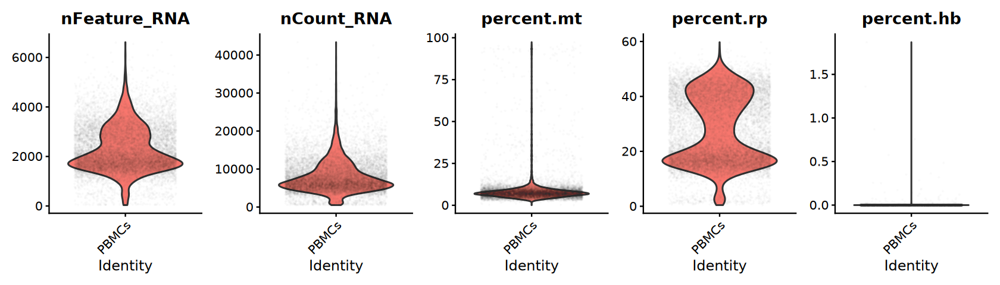

In [12]:
options(repr.plot.width = 14, repr.plot.height = 4)
VlnPlot(sc.temp, layer = "counts", group.by = "orig.ident",
        features = c("nFeature_RNA", "nCount_RNA", "percent.mt", 
                     "percent.rp", "percent.hb"), 
        pt.size = 0.01, alpha = 0.01, ncol = 5) & NoLegend()

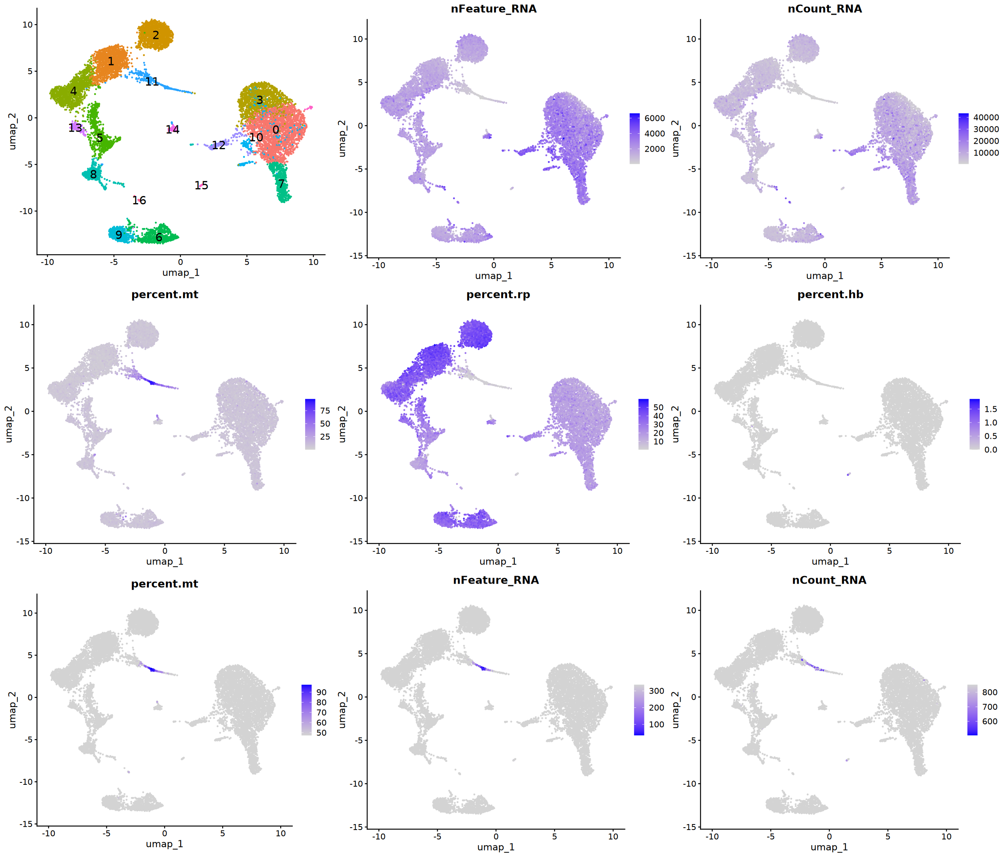

In [13]:
p1 <- DimPlot(
    sc.temp, reduction = "umap", label = TRUE, 
    label.size = 6) & NoLegend()
p2 <- FeaturePlot(
    sc.temp, reduction = "umap", combine = FALSE,
    features = c("nFeature_RNA", "nCount_RNA", "percent.mt", 
                 "percent.rp", "percent.hb"))
p3 <- FeaturePlot(
    sc.temp, reduction = "umap", features = "percent.mt",
    min.cutoff = "q99", order = TRUE)
p4 <- FeaturePlot(
    sc.temp, reduction = "umap", combine = FALSE,
    features = c("nFeature_RNA", "nCount_RNA"),
    max.cutoff = "q1", cols = c("blue", "lightgrey"))

options(repr.plot.width = 21, repr.plot.height = 18)
plot_grid(plotlist = c(p1, p2, p3, p4), ncol = 3)

In [14]:
source("R/calculate_mad_threshold.R")

In [15]:
cat(sprintf("Counts: Lower: %d\n", calculate_mad_threshold(
    sc.temp$nCount_RNA, nmads = 3, sides = "lower")))

cat(sprintf("Features: Lower: %d\n", calculate_mad_threshold(
    sc.temp$nFeature_RNA, nmads = 3, sides = "lower")))

cat(sprintf("Mitochondrial: Upper: %d\n", calculate_mad_threshold(
    sc.temp$percent.mt, nmads = 3, sides = "upper")))

Counts: Lower: 1679
Features: Lower: 592
Mitochondrial: Upper: 17


## 3). Filtering Low-quality Cells

In [16]:
scrna <- subset(
    scrna, 
    subset = nFeature_RNA > 500 & percent.mt < 20)
scrna

An object of class Seurat 
22302 features across 11666 samples within 1 assay 
Active assay: RNA (22302 features, 0 variable features)
 1 layer present: counts

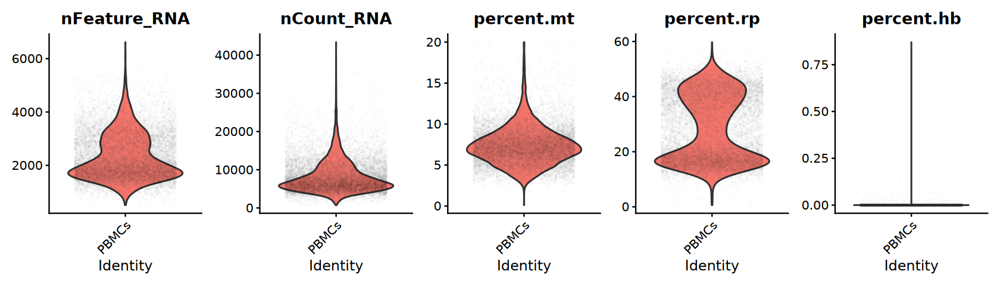

In [17]:
options(repr.plot.width = 14, repr.plot.height = 4)
VlnPlot(scrna, layer = "counts", group.by = "orig.ident",
        features = c("nFeature_RNA", "nCount_RNA", "percent.mt", 
                     "percent.rp", "percent.hb"), 
        pt.size = 0.01, alpha = 0.01, ncol = 5) & NoLegend()

## 4). Doublet Detection

### a). [DoubletFinder](https://github.com/chris-mcginnis-ucsf/DoubletFinder)

In [18]:
source("R/run_DoubletFinder.R")

In [19]:
scrna <- run_DoubletFinder(
    scrna, ndim = 20, clusters = "seurat_clusters", 
    multiplet.rate = 0.008, seed = 123)

[1] "Creating 3889 artificial doublets..."
[1] "Classifying doublets.."


DoubletFinder completed: pN = 0.25, pK = 0.28, nExp_adj = 961



In [20]:
table(scrna$DoubletFinder.class)


Singlet Doublet 
  10705     961 

### b). [scDblFinder](https://github.com/plger/scDblFinder)

In [21]:
suppressPackageStartupMessages(library(scDblFinder))

In [22]:
set.seed(123)
sce <- run_seurat_pipeline(scrna, ndim = 20) |>
    as.SingleCellExperiment() |>
    scDblFinder(clusters = "seurat_clusters", verbose = FALSE)

In [23]:
scrna$scDblFinder.score <- colData(sce)$scDblFinder.score
scrna$scDblFinder.class <- colData(sce)$scDblFinder.class

In [24]:
table(scrna$scDblFinder.class)


singlet doublet 
  10796     870 

### Filtering Doublets

In [25]:
sc.temp <- run_seurat_pipeline(scrna, ndim = 20)

In [26]:
table(scDblFinder = sc.temp$scDblFinder.class, 
      DoubletFinder = sc.temp$DoubletFinder.class)

           DoubletFinder
scDblFinder Singlet Doublet
    singlet   10265     531
    doublet     440     430

In [27]:
sc.temp$isDoublet <- apply(
    sc.temp@meta.data[, c(
        "scDblFinder.class", "DoubletFinder.class")],
    1, function(x) paste(x, collapse = "_")
    ) |> as.factor()

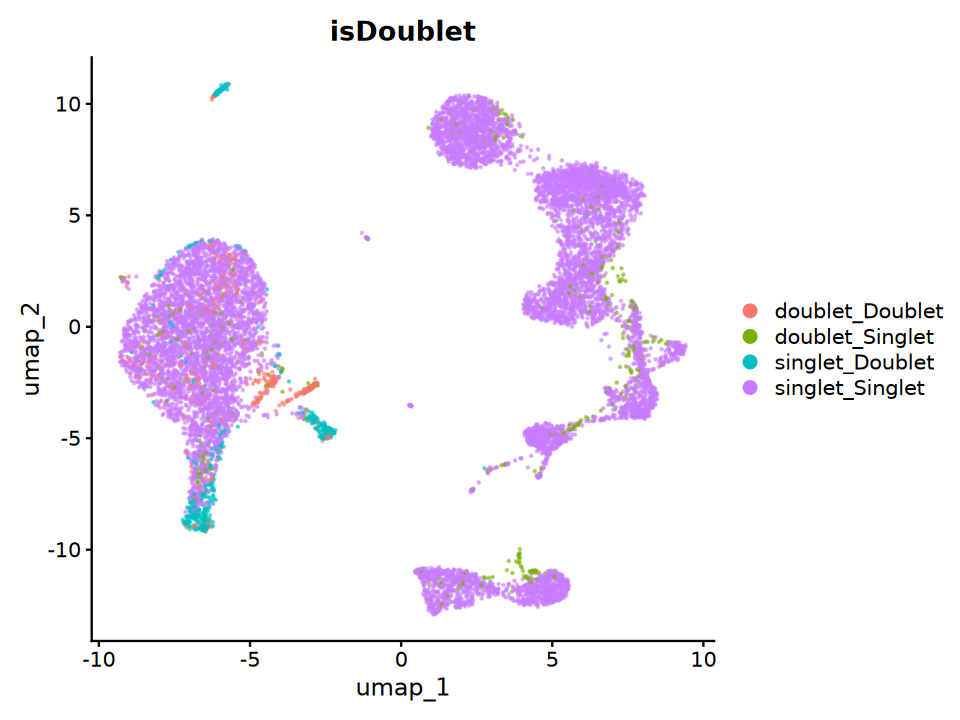

In [28]:
options(repr.plot.width = 8, repr.plot.height = 6)
DimPlot(sc.temp, reduction = "umap",
        group.by = "isDoublet", 
        pt.size = 0.1, alpha = 0.5)

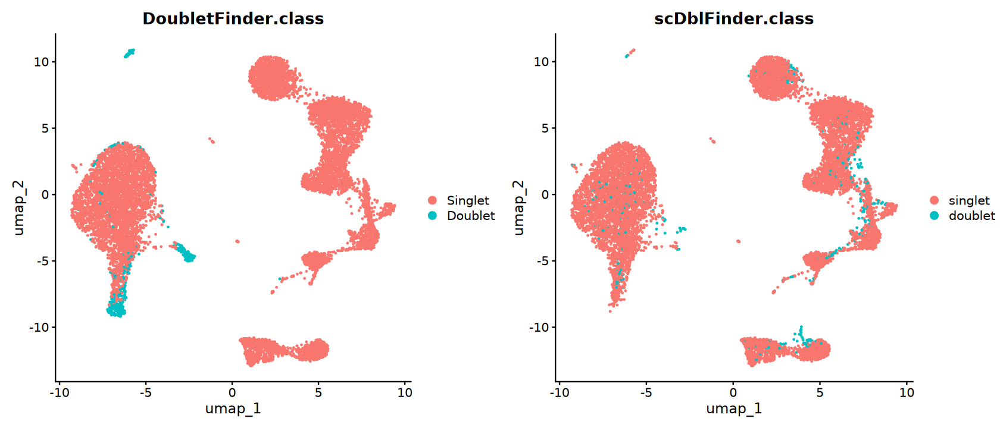

In [29]:
p1 <- DimPlot(
    subset(sc.temp, subset = scDblFinder.class == "singlet"),
    reduction = "umap", group.by = "DoubletFinder.class")
p2 <- DimPlot(
    subset(sc.temp, subset = DoubletFinder.class == "Singlet"), 
    reduction = "umap", group.by = "scDblFinder.class")

options(repr.plot.width = 14, repr.plot.height = 6)
plot_grid(p1, p2, ncol = 2)

In [30]:
sc.temp <- subset(
    sc.temp, 
    subset = DoubletFinder.class == "Singlet" |
        scDblFinder.class == "singlet")
sc.temp

An object of class Seurat 
22302 features across 11236 samples within 1 assay 
Active assay: RNA (22302 features, 2000 variable features)
 3 layers present: counts, data, scale.data
 3 dimensional reductions calculated: pca, umap, tsne

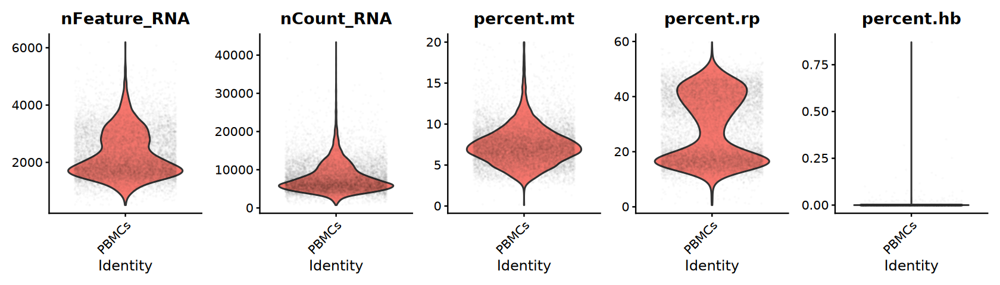

In [31]:
options(repr.plot.width = 14, repr.plot.height = 4)
VlnPlot(sc.temp, layer = "counts", group.by = "orig.ident",
        features = c("nFeature_RNA", "nCount_RNA", "percent.mt", 
                     "percent.rp", "percent.hb"), 
        pt.size = 0.01, alpha = 0.01, ncol = 5) & NoLegend()

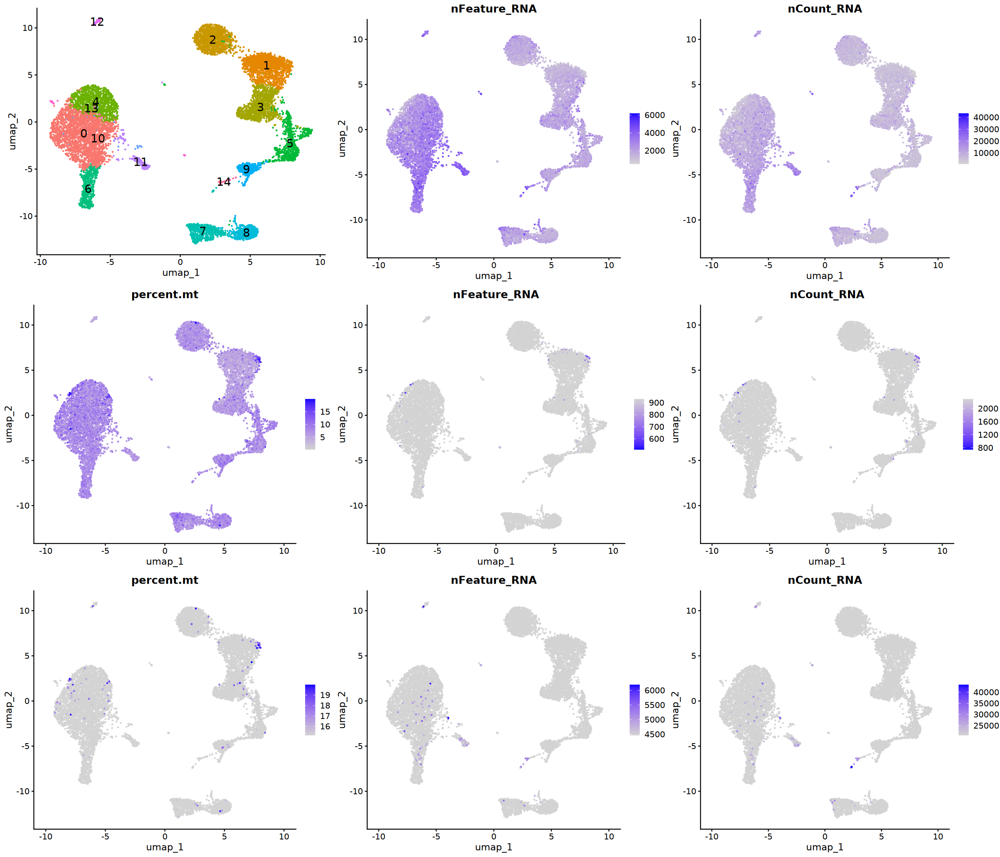

In [32]:
p1 <- DimPlot(
    sc.temp, reduction = "umap", label = TRUE, 
    label.size = 6) & NoLegend()
p2 <- FeaturePlot(
    sc.temp, reduction = "umap", combine = FALSE,
    features = c("nFeature_RNA", "nCount_RNA", "percent.mt"))
p3 <- FeaturePlot(
    sc.temp, reduction = "umap", combine = FALSE,
    features = c("nFeature_RNA", "nCount_RNA"),
    max.cutoff = "q1", cols = c("blue", "lightgrey"))
p4 <- FeaturePlot(
    sc.temp, reduction = "umap",
    features = c("percent.mt", "nFeature_RNA", "nCount_RNA"),
    min.cutoff = "q99", order = TRUE, combine = FALSE)

options(repr.plot.width = 21, repr.plot.height = 18)
plot_grid(plotlist = c(p1, p2, p3, p4), ncol = 3, byrow = TRUE)

In [33]:
summary(sc.temp@meta.data[, c("nFeature_RNA", "nCount_RNA", "percent.mt")])

  nFeature_RNA    nCount_RNA      percent.mt     
 Min.   : 510   Min.   :  745   Min.   : 0.1129  
 1st Qu.:1643   1st Qu.: 5268   1st Qu.: 5.8191  
 Median :2040   Median : 6863   Median : 7.1424  
 Mean   :2251   Mean   : 7847   Mean   : 7.3703  
 3rd Qu.:2822   3rd Qu.: 9583   3rd Qu.: 8.5782  
 Max.   :6193   Max.   :43373   Max.   :19.9895  

In [34]:
cat(sprintf("Counts: Upper: %d\n", calculate_mad_threshold(
    sc.temp$nCount_RNA, nmads = 3, sides = "upper")))

cat(sprintf("Features: Upper: %d\n", calculate_mad_threshold(
    sc.temp$nFeature_RNA, nmads = 3, sides = "upper")))

Counts: Upper: 25394
Features: Upper: 6547


In [35]:
scrna <- scrna |>
    subset(
        subset = DoubletFinder.class == "Singlet" |
            scDblFinder.class == "singlet") |>
    subset(
        subset = nCount_RNA < 25000 & 
            percent.mt < 20 & percent.hb < 1)
scrna

An object of class Seurat 
22302 features across 11190 samples within 1 assay 
Active assay: RNA (22302 features, 0 variable features)
 1 layer present: counts

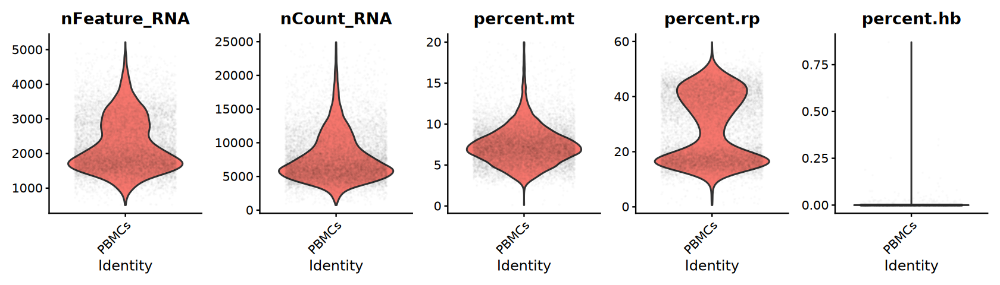

In [36]:
options(repr.plot.width = 14, repr.plot.height = 4)
VlnPlot(scrna, layer = "counts", group.by = "orig.ident",
        features = c("nFeature_RNA", "nCount_RNA", "percent.mt",
                     "percent.rp", "percent.hb"), 
        pt.size = 0.01, alpha = 0.01, ncol = 5) & NoLegend()

## 5). Evaluating Noise

### a). Cell cycle effect

In [37]:
str(cc.genes)

List of 2
 $ s.genes  : chr [1:43] "MCM5" "PCNA" "TYMS" "FEN1" ...
 $ g2m.genes: chr [1:54] "HMGB2" "CDK1" "NUSAP1" "UBE2C" ...


In [38]:
scrna <- NormalizeData(scrna, verbose = FALSE) |> 
    CellCycleScoring(s.features = cc.genes$s.genes,
                     g2m.features = cc.genes$g2m.genes)

Warning message:
“The following features are not present in the object: MLF1IP, not searching for symbol synonyms”
Warning message:
“The following features are not present in the object: FAM64A, HN1, not searching for symbol synonyms”


### b). Cell dissociation effect

In [39]:
dissociation_genes <- readLines(
    "~/data1/single_cell_dataset/reference_infomation/dissociation_genes.txt")
str(dissociation_genes)

 chr [1:140] "Actg1" "Btg1" "Cxcl1" "Dnajb4" "Errfi1" "H3f3b" "Hspb1" ...


In [40]:
scrna <- AddModuleScore(
    scrna, name = "Dissociation.Score", 
    features = list(
        dissociationGenes = toupper(dissociation_genes)))
# rename
scrna@meta.data <- scrna@meta.data |> 
    dplyr::rename("Dis.Score" = "Dissociation.Score1")

Warning message:
“The following features are not present in the object: ANKRD1, CYR61, FAM132B, MT1, DCN, MT2, CCRN4L, NPPC, not searching for symbol synonyms”


# 3. Initial Assessment

In [41]:
sc.temp <- run_seurat_pipeline(scrna, ndim = 20)

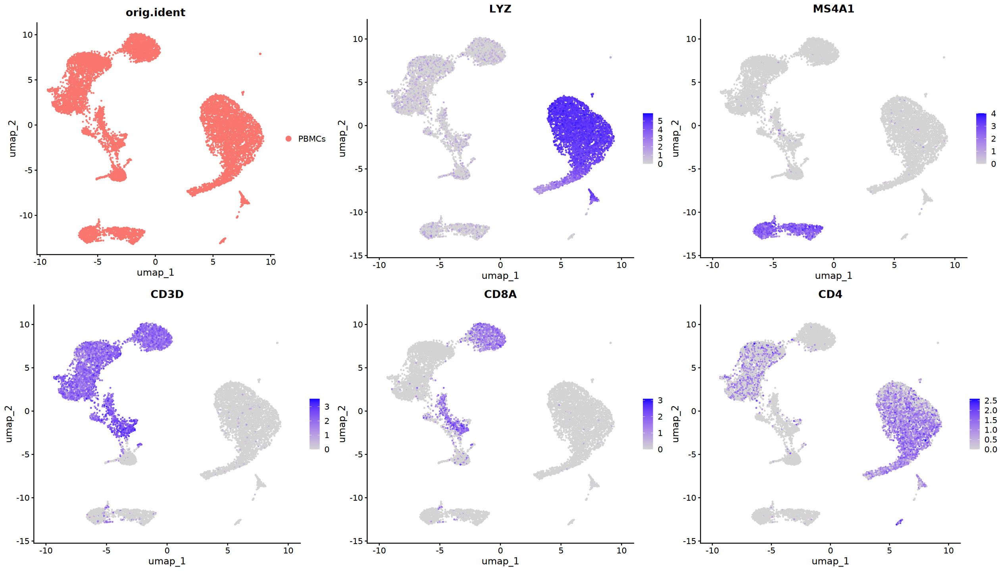

In [42]:
geneset <- c("LYZ", "MS4A1", "CD3D", "CD8A", "CD4")
p1 <- DimPlot(
    sc.temp, reduction = "umap", group.by = "orig.ident")
p2 <- FeaturePlot(
    sc.temp, reduction = "umap", features = geneset,
    combine = FALSE)

options(repr.plot.width = 21, repr.plot.height = 12)
plot_grid(plotlist = c(p1, p2), ncol = 3)

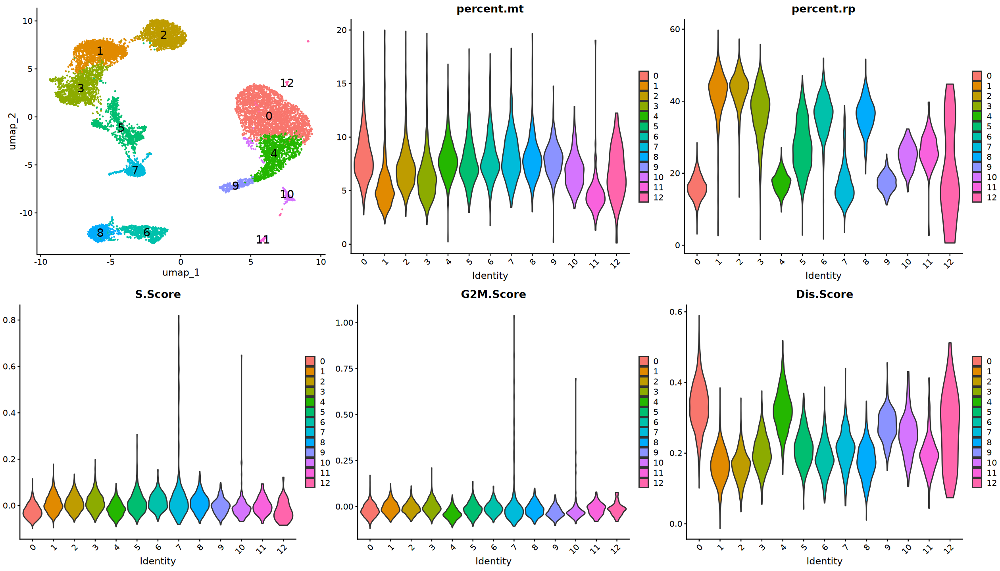

In [43]:
p1 <- DimPlot(
    sc.temp, reduction = "umap", label = TRUE, 
    label.size = 6) & NoLegend()
p2 <- VlnPlot(
    sc.temp, features = c("percent.mt", "percent.rp"), 
    group.by = "seurat_clusters", pt.size = 0, combine = FALSE)
p3 <- VlnPlot(
    sc.temp, features = c("S.Score", "G2M.Score", "Dis.Score"), 
    group.by = "seurat_clusters", pt.size = 0, combine = FALSE)

options(repr.plot.width = 21, repr.plot.height = 12)
plot_grid(plotlist = c(p1, p2, p3), ncol = 3)

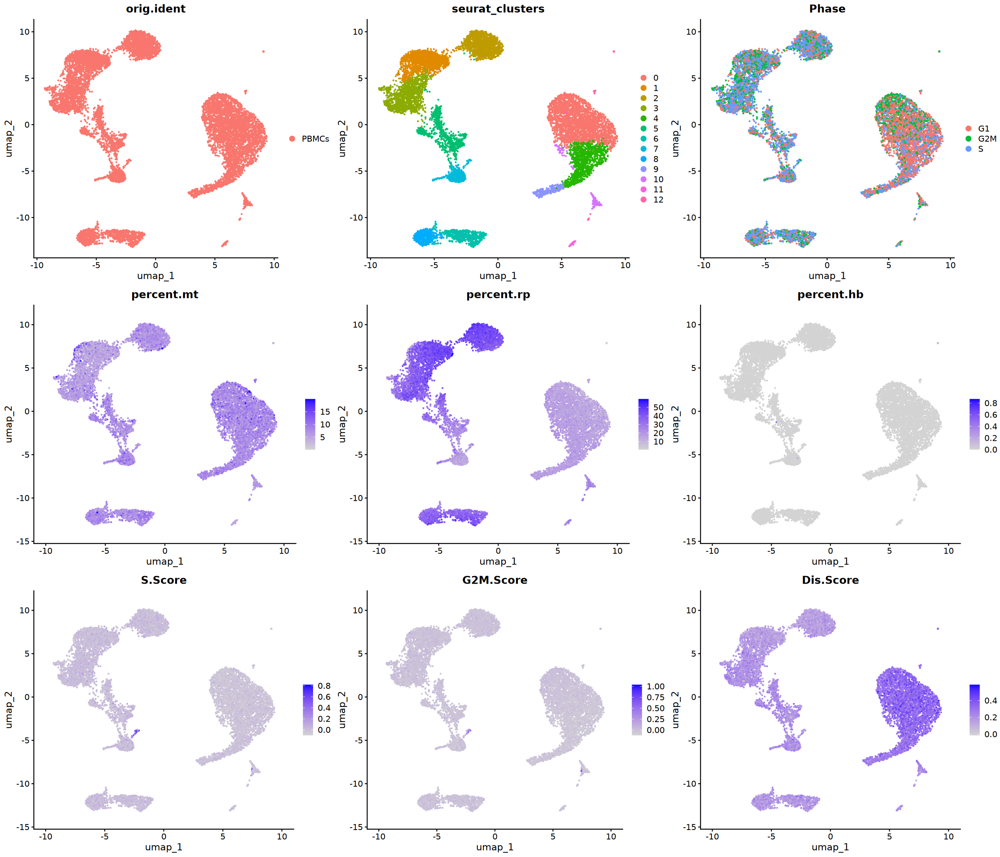

In [44]:
p1 <- DimPlot(
    sc.temp, reduction = "umap", combine = FALSE,
    group.by = c("orig.ident", "seurat_clusters", "Phase"))
p2 <- FeaturePlot(
    sc.temp, reduction = "umap", combine = FALSE,
    features = c("percent.mt", "percent.rp", "percent.hb", 
                 "S.Score", "G2M.Score", "Dis.Score"))

options(repr.plot.width = 21, repr.plot.height = 18)
plot_grid(plotlist = c(p1, p2), ncol = 3)

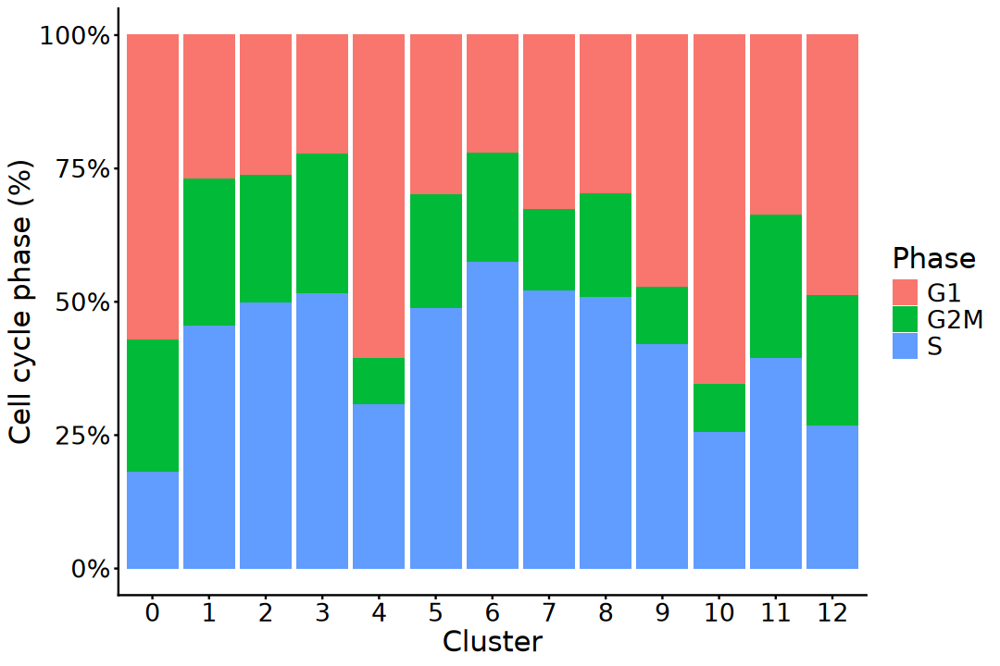

In [45]:
options(repr.plot.width = 9, repr.plot.height = 6)
table(sc.temp$seurat_clusters, sc.temp$Phase) |> 
    as.data.frame() |>
    ggplot(aes(x = Var1, y = Freq, fill = Var2)) +
        geom_bar(stat = "identity", position = "fill") +
        scale_y_continuous(labels = scales::percent_format()) +
        labs(x = "Cluster", y = "Cell cycle phase (%)", 
             fill = "Phase") +
        theme_classic() + 
        theme(axis.title = element_text(size = 18),
              axis.text = element_text(size = 16),
              legend.title = element_text(size = 18),
              legend.text = element_text(size = 16))

In [46]:
pca <- Embeddings(sc.temp, "pca")[, 1:10]

vars <- c("nCount_RNA", "percent.mt", "percent.rp", "percent.hb", 
          "S.Score", "G2M.Score", "Dis.Score")

cors <- sapply(vars, function(v) {
    apply(pca, 2, cor, y = sc.temp[[v]], method = "pearson")
}) |> t()

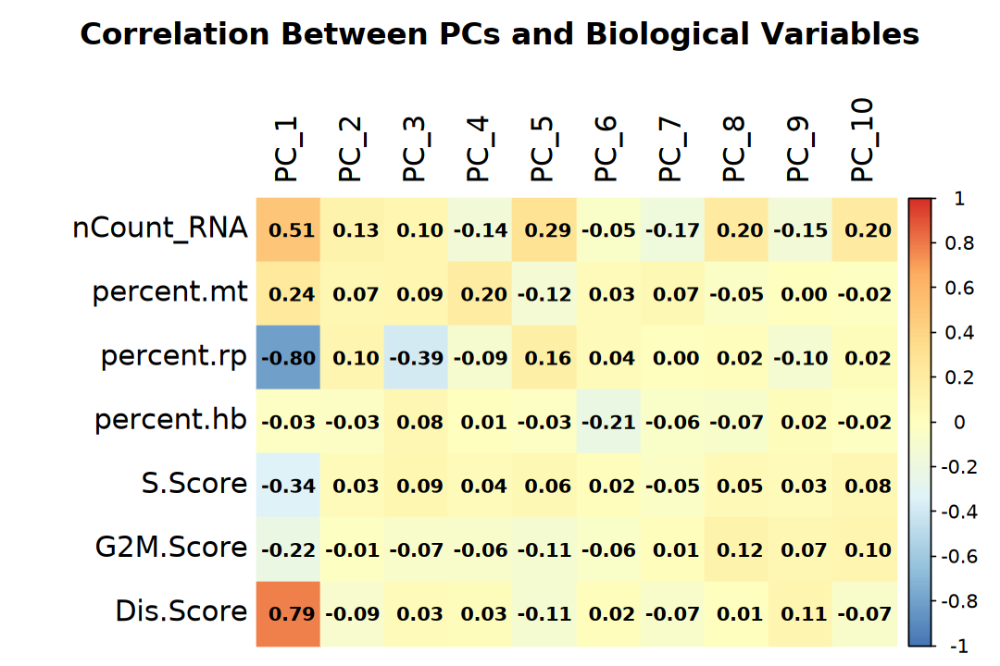

In [47]:
options(repr.plot.width = 9, repr.plot.height = 6)

gradient_colors <- colorRampPalette(
    c("#4575B4", "#91BFDB", "#E0F3F8", "#FFFFBF", 
      "#FEE090", "#FDAE61", "#D73027"))(200)

corrplot::corrplot(cors, method = "color",
                   col = gradient_colors, cl.cex = 1, 
                   col.lim = c(-1, 1),
                   title = "Correlation Between PCs and Biological Variables",
                   cex.main = 1.6, col.main = "black",
                   tl.col = "black", tl.cex = 1.5,
                   addCoef.col = "black", number.cex = 1, 
                   is.corr = FALSE, mar = c(0, 0, 3, 0))

# 4. Normalization

In [48]:
scrna

An object of class Seurat 
22302 features across 11190 samples within 1 assay 
Active assay: RNA (22302 features, 0 variable features)
 2 layers present: counts, data

## a). LogNormalize

In [49]:
# Normalizate: log1p(counts per 10k)
scrna <- NormalizeData(
    scrna, normalization.method = "LogNormalize", 
    scale.factor = 10000)
scrna

Normalizing layer: counts



An object of class Seurat 
22302 features across 11190 samples within 1 assay 
Active assay: RNA (22302 features, 0 variable features)
 2 layers present: counts, data

In [50]:
### 2). Feature selection: Number of features: 2000 ~ 5000
scrna <- FindVariableFeatures(
    scrna, selection.method = "vst", nfeatures = 3000)
scrna

Finding variable features for layer counts



An object of class Seurat 
22302 features across 11190 samples within 1 assay 
Active assay: RNA (22302 features, 3000 variable features)
 2 layers present: counts, data

In [51]:
HVFInfo(scrna, status = TRUE) |>
    arrange(desc(variance.standardized)) |> 
    head()

,mean,variance,variance.expected,variance.standardized,variable,rank
,<dbl>,<dbl>,<dbl>,<dbl>,<lgl>,<int>
IGLC3,0.6176944,65.04786,0.9603966,26.53304,TRUE,1
IGLC1,0.3624665,15.70201,0.4914644,25.32913,TRUE,2
PTGDS,0.3972297,60.15098,0.5496528,24.45819,TRUE,3
IGLC2,1.3296693,689.33728,2.8244335,23.03106,TRUE,4
CXCL10,0.6016086,30.51961,0.9278987,18.77985,TRUE,5
PPBP,0.2165326,32.14535,0.2692721,18.25586,TRUE,6


Warning message in scale_x_log10():
“log-10 transformation introduced infinite values.”


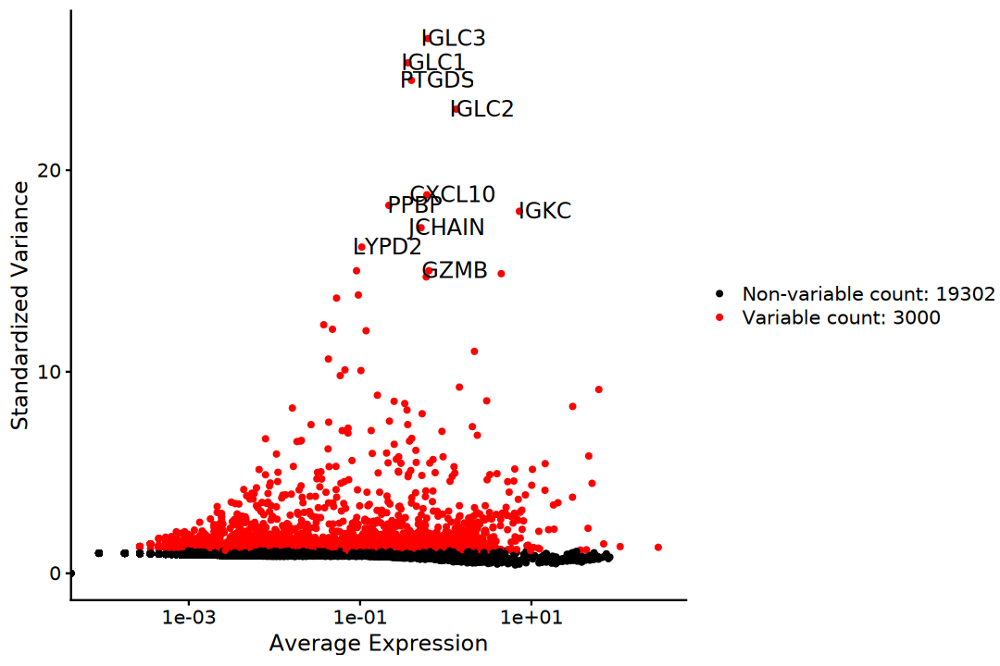

In [52]:
options(repr.plot.width = 9, repr.plot.height = 6)
# plot variable features with and without labels
VariableFeaturePlot(scrna) |> 
    LabelPoints(points = VariableFeatures(scrna)[1:10])

In [53]:
# Scaling
sc.temp <- ScaleData(
    scrna, features = Features(scrna), 
    vars.to.regress = "percent.mt")
sc.temp

Regressing out percent.mt

Centering and scaling data matrix



An object of class Seurat 
22302 features across 11190 samples within 1 assay 
Active assay: RNA (22302 features, 3000 variable features)
 3 layers present: counts, data, scale.data

In [54]:
source("R/scale_data_chunked.R")

In [55]:
scrna <- scale_data_chunked(
    scrna, features = Features(scrna), 
    vars.to.regress = "percent.mt")
scrna

An object of class Seurat 
22302 features across 11190 samples within 1 assay 
Active assay: RNA (22302 features, 3000 variable features)
 3 layers present: counts, data, scale.data

In [56]:
scaledata1 <- LayerData(sc.temp, assay = "RNA", layer = "scale.data")
scaledata2 <- LayerData(scrna, assay = "RNA", layer = "scale.data")

In [57]:
identical(scaledata1, scaledata2) && all(scaledata1 == scaledata2)

[1] TRUE

## b). SCTransform

In [58]:
# # SCT v1
# scrna <- SCTransform(
#     scrna, return.only.var.genes = FALSE,
#     vars.to.regress = "percent.mt",
#     vst.flavor = "v1", verbose = FALSE)
# SCT v2
scrna <- SCTransform(
    scrna, return.only.var.genes = FALSE,
    vars.to.regress = "percent.mt")
scrna

Running SCTransform on assay: RNA

vst.flavor='v2' set. Using model with fixed slope and excluding poisson genes.

Calculating cell attributes from input UMI matrix: log_umi

Variance stabilizing transformation of count matrix of size 20513 by 11190

Model formula is y ~ log_umi

Get Negative Binomial regression parameters per gene

Using 2000 genes, 5000 cells

Found 222 outliers - those will be ignored in fitting/regularization step


Second step: Get residuals using fitted parameters for 20513 genes

Computing corrected count matrix for 20513 genes

Calculating gene attributes

Wall clock passed: Time difference of 31.58971 secs

Determine variable features

Regressing out percent.mt

Centering data matrix

Place corrected count matrix in counts slot

Set default assay to SCT



An object of class Seurat 
42815 features across 11190 samples within 2 assays 
Active assay: SCT (20513 features, 3000 variable features)
 3 layers present: counts, data, scale.data
 1 other assay present: RNA

In [59]:
DefaultAssay(scrna) <- "RNA"
scrna

An object of class Seurat 
42815 features across 11190 samples within 2 assays 
Active assay: RNA (22302 features, 3000 variable features)
 3 layers present: counts, data, scale.data
 1 other assay present: SCT

In [60]:
saveRDS(scrna, file.path(
    data_dir, "result", "s4_normalization_seurat_V5.rds"))

# 5. Linear Dimensionality Reduction

In [61]:
scrna <- RunPCA(
    scrna, features = VariableFeatures(scrna), npcs = 50)

PC_ 1 
Positive:  FGL2, FCN1, LYZ, CST3, MNDA, CTSS, TYMP, CYBB, SERPINA1, IFI30 
	   PSAP, NCF2, S100A9, LST1, TYROBP, AIF1, MPEG1, CSTA, TNFSF13B, TMEM176B 
	   DUSP6, FTL, CD68, GRN, MS4A6A, FOS, S100A8, AC020656.1, DUSP1, IGSF6 
Negative:  RPS18, LTB, CD3E, IL32, CD3D, TRAC, CD3G, PCED1B-AS1, TRBC2, ETS1 
	   BCL11B, MALAT1, IL7R, LDHB, LCK, ARL4C, CD2, LBH, LIME1, TCF7 
	   CD7, LINC00861, PRKCQ-AS1, FCMR, CD27, SPOCK2, CCR7, PIK3IP1, CLEC2D, SLC38A1 
PC_ 2 
Positive:  MS4A1, CD79A, IGHM, BANK1, CD79B, LINC00926, RALGPS2, NIBAN3, TNFRSF13C, BCL11A 
	   IGHD, HLA-DQA1, SPIB, IGKC, CD22, AFF3, LINC02397, PAX5, VPREB3, FCRL1 
	   CD74, BLK, HLA-DRA, FCER2, HLA-DRB1, COBLL1, TCF4, BLNK, SWAP70, HLA-DPB1 
Negative:  FYB1, IL32, CD3E, CD3D, GZMM, CD3G, CTSW, CD2, ANXA1, CD247 
	   CD7, BCL11B, GZMA, LCK, S100A4, TRAC, NKG7, CST7, PRF1, LINC00861 
	   GNLY, CCL5, KLRK1, IL7R, KLRD1, LAT, ARL4C, SAMD3, TMSB4X, TRBC1 
PC_ 3 
Positive:  CCR7, LEF1, IL7R, TCF7, PIK3IP1, MAL, TRABD2A, RCAN3, 

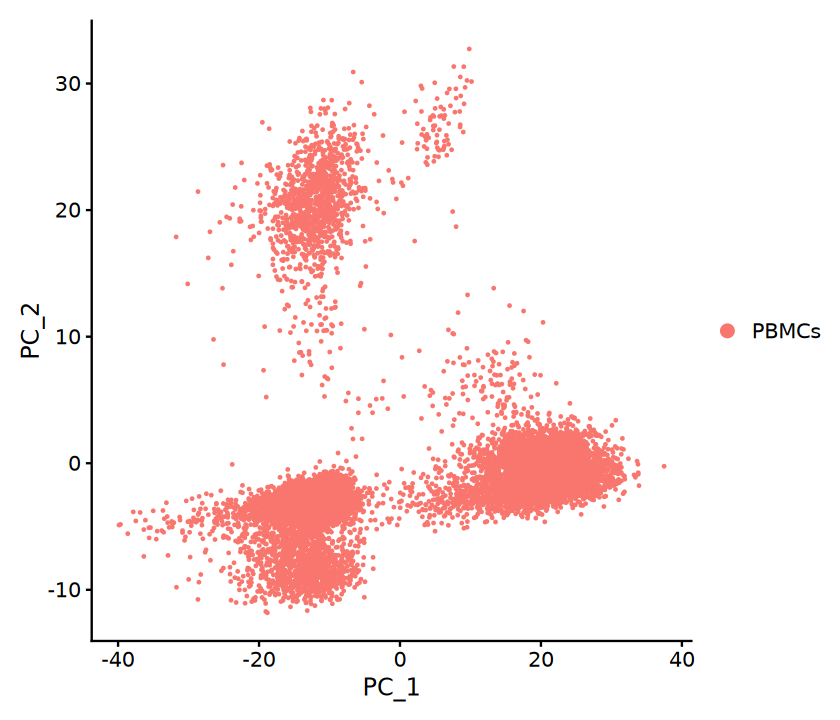

In [62]:
options(repr.plot.width = 7, repr.plot.height = 6)
DimPlot(scrna, reduction = "pca")

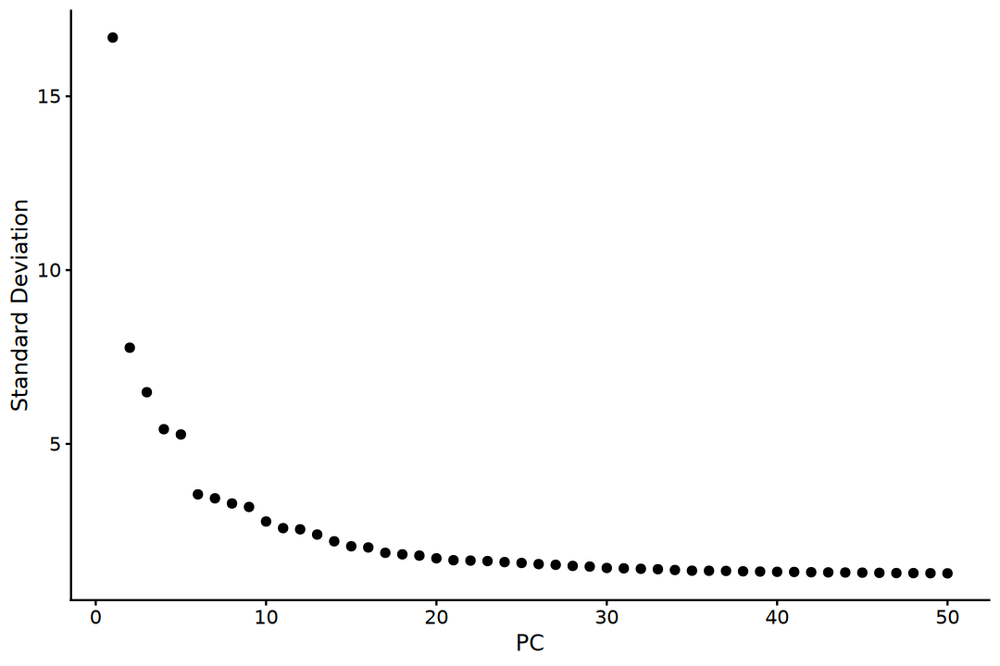

In [63]:
# Elbow plot
options(repr.plot.width = 9, repr.plot.height = 6)
ElbowPlot(scrna, ndims = 50)

In [64]:
# Estimating PCA dimensionality
pca_var <- scrna@reductions$pca@stdev ^ 2
pca_con <- pca_var / sum(pca_var)
nPCs <- which(cumsum(pca_con) > 0.9 & pca_con < 0.05)[1]
print(nPCs)

[1] 21


In [65]:
# Determine statistical significance of PCA scores.
sc.temp <- JackStraw(scrna, dims = 20, num.replicate = 100)

In [66]:
# Compute Jackstraw scores significance.
sc.temp <- ScoreJackStraw(sc.temp, dims = 1:20)

Warning message:
“Removed 42000 rows containing missing values or values outside the scale range (`geom_point()`).”


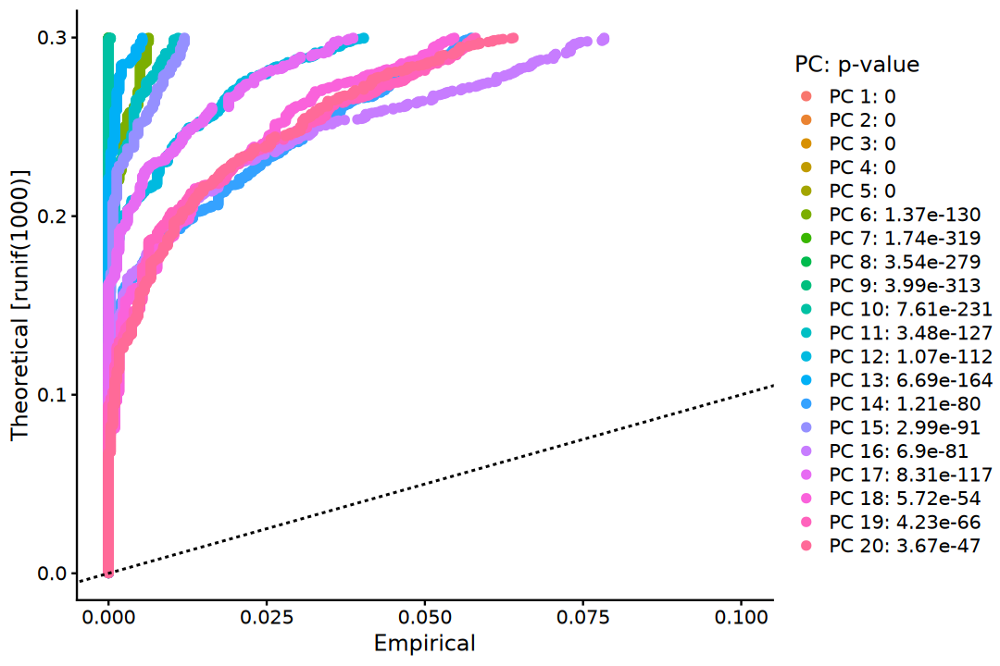

In [67]:
# JackStraw Plot
options(repr.plot.width = 9, repr.plot.height = 6)
JackStrawPlot(sc.temp, dims = 1:20)

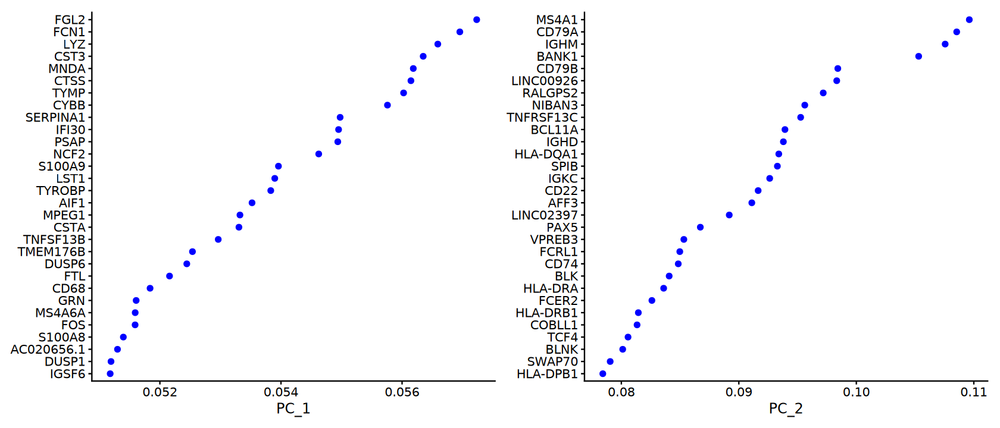

In [68]:
# Gene information
options(repr.plot.width = 14, repr.plot.height = 6)
VizDimLoadings(scrna, dims = 1:2, reduction = "pca", ncol = 2)

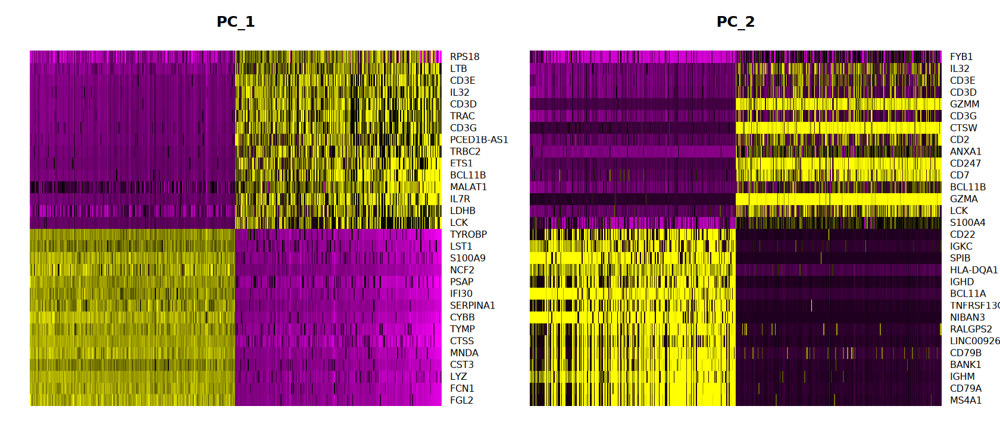

In [69]:
options(repr.plot.width = 14, repr.plot.height = 6)
DimHeatmap(scrna, dims = 1:2, cells = 500, balanced = TRUE)

In [70]:
source("R/compare_npcs_clustering.R")

In [71]:
plots <- compare_npcs_clustering(
    scrna, reduction = "pca", method = "umap")

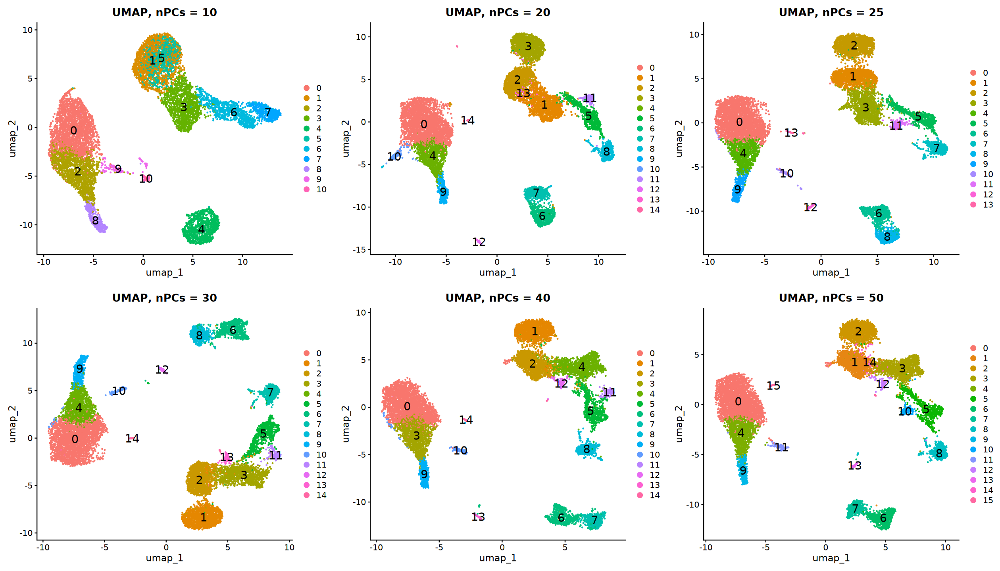

In [72]:
options(repr.plot.width = 21, repr.plot.height = 12)
plot_grid(plotlist = plots, ncol = 3)

In [73]:
nPCs <- 30

# 6. Integration (Skip)

# 7. Neighborhood Graph Construction

In [74]:
scrna <- FindNeighbors(
    scrna, features = VariableFeatures(scrna), k.param = 20,
    reduction = "pca", dims = seq_len(nPCs))

Computing nearest neighbor graph

Computing SNN



# 8. Non-linear Dimensionality Reduction

In [75]:
scrna <- RunUMAP(
    scrna, dims = seq_len(nPCs), reduction = "pca", 
    verbose = FALSE)

In [76]:
scrna <- RunTSNE(
    scrna, dims = seq_len(nPCs), reduction = "pca")

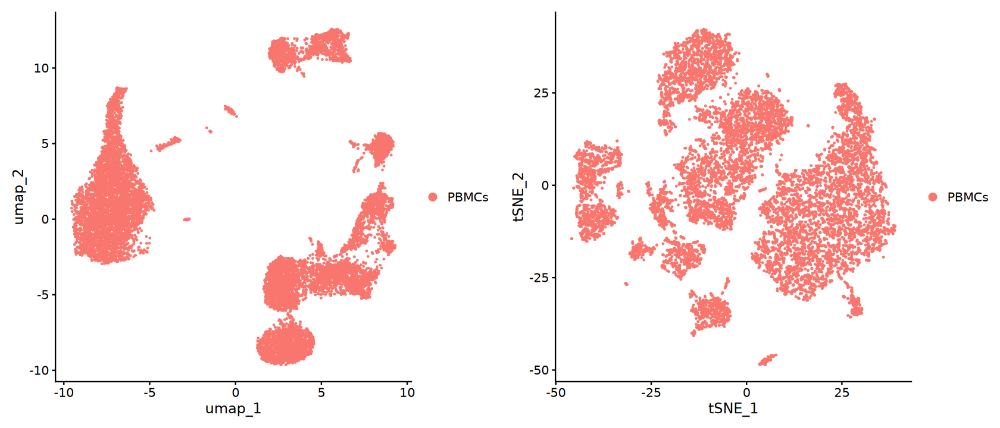

In [77]:
p1 <- DimPlot(scrna, reduction = "umap")
p2 <- DimPlot(scrna, reduction = "tsne")

options(repr.plot.width = 14, repr.plot.height = 6)
plot_grid(p1, p2, ncol = 2)

# 9. Clustering

## 1). Resolution Tuning

In [78]:
source("R/scan_clustering_resolution.R")

In [79]:
cluster_list <- scan_clustering_resolution(
    scrna, reduction = "pca", dims = nPCs,
    resolution = seq(0.1, 0.9, 0.1))

Registered S3 method overwritten by 'pROC':
  method   from            
  plot.roc spatstat.explore



In [80]:
metrics_df <- cluster_list$metrics |>
    mutate(accuracy = round(accuracy * 100, 2), 
           f1 = round(f1 * 100, 2),
           silhouette = round(silhouette * 100, 2),
           modularity = round(modularity * 100, 2))
metrics_df

,resolution,n_cluster,accuracy,f1,silhouette,modularity
,<dbl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>
res_0.1,0.1,8,91.02,99.27,23.15,75.78
res_0.2,0.2,10,86.28,97.24,22.99,77.90
res_0.3,0.3,12,78.87,98.00,21.16,80.71
res_0.4,0.4,14,67.94,94.31,18.95,82.34
res_0.5,0.5,15,68.84,87.98,15.77,83.36
res_0.6,0.6,16,68.60,88.73,16.01,83.42
res_0.7,0.7,16,69.93,89.60,16.00,83.42
res_0.8,0.8,17,69.48,88.40,16.04,83.39
res_0.9,0.9,17,70.24,82.04,15.43,83.61


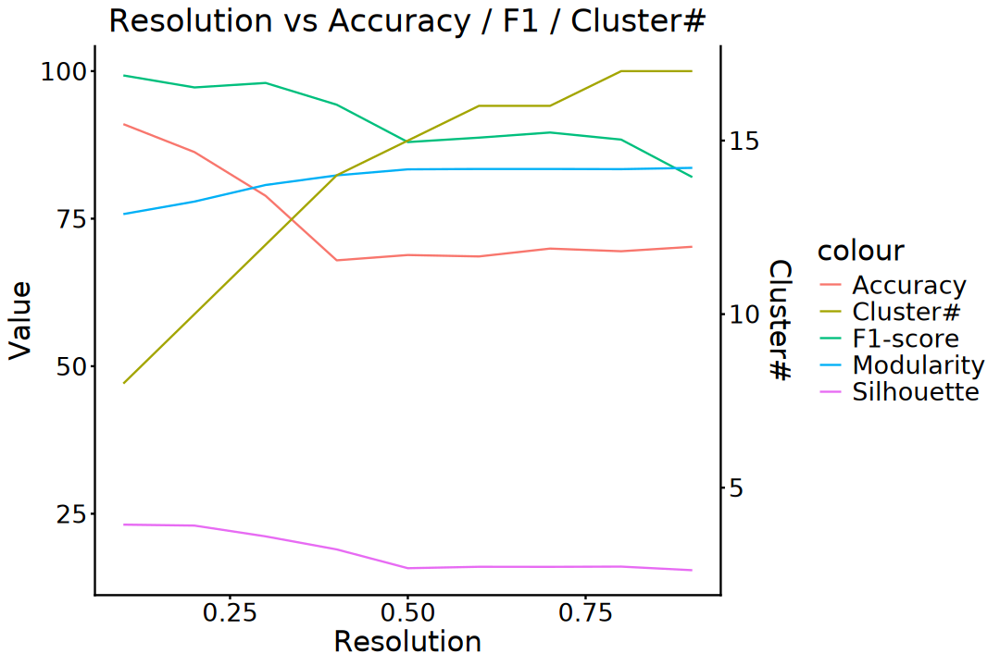

In [81]:
options(repr.plot.width = 9, repr.plot.height = 6)
ggplot(metrics_df, aes(x = resolution)) +
    geom_line(aes(y = accuracy, color = "Accuracy")) +
    geom_line(aes(y = f1, color = "F1-score")) +
    geom_line(aes(y = silhouette, color = "Silhouette")) +
    geom_line(aes(y = modularity, color = "Modularity")) +
    geom_line(aes(y = n_cluster/ max(n_cluster)*100, 
                  color = "Cluster#")) +
    scale_y_continuous(
        name = "Value", 
        sec.axis = sec_axis(
            ~./100*max(metrics_df$n_cluster), name = "Cluster#")) +
    ggtitle("Resolution vs Accuracy / F1 / Cluster#") + 
    labs(x = "Resolution") +
    theme_classic() +
    theme(plot.title =  element_text(size = 20, hjust = 0.5),
          axis.title = element_text(size = 18),
          axis.text = element_text(size = 16),
          legend.title = element_text(size = 18),
          legend.text = element_text(size = 16))

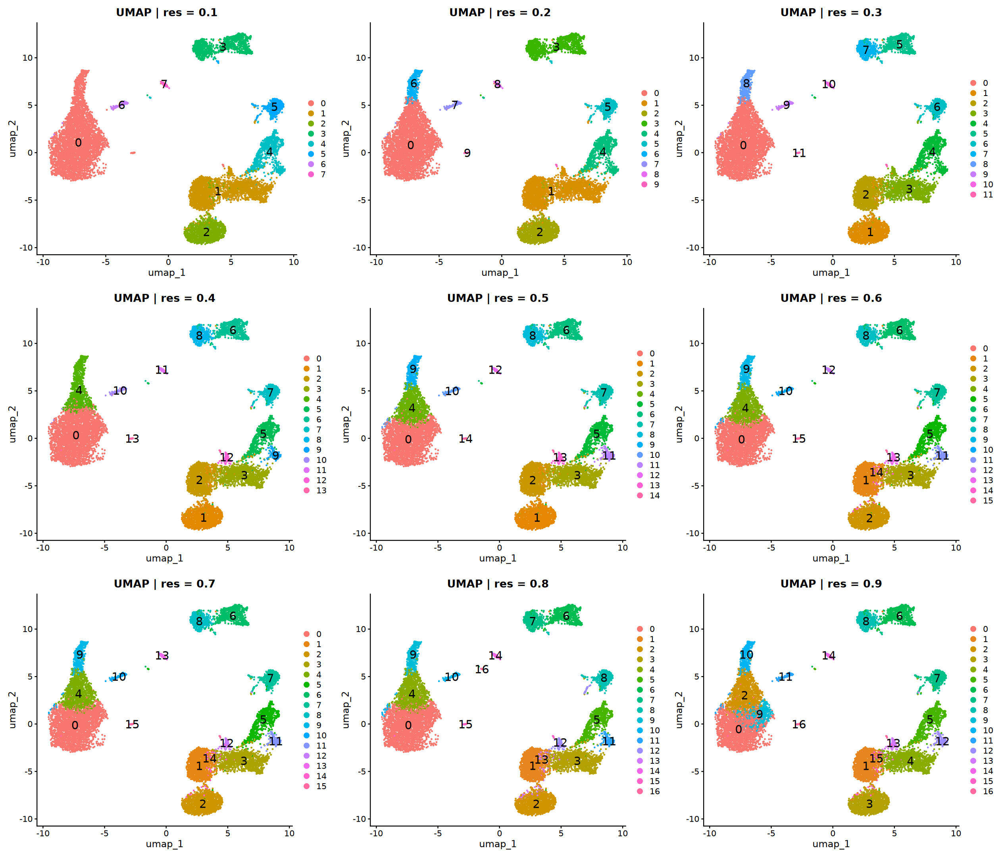

In [82]:
options(repr.plot.width = 21, repr.plot.height = 18)
plot_grid(plotlist = cluster_list$umap, ncol = 3)

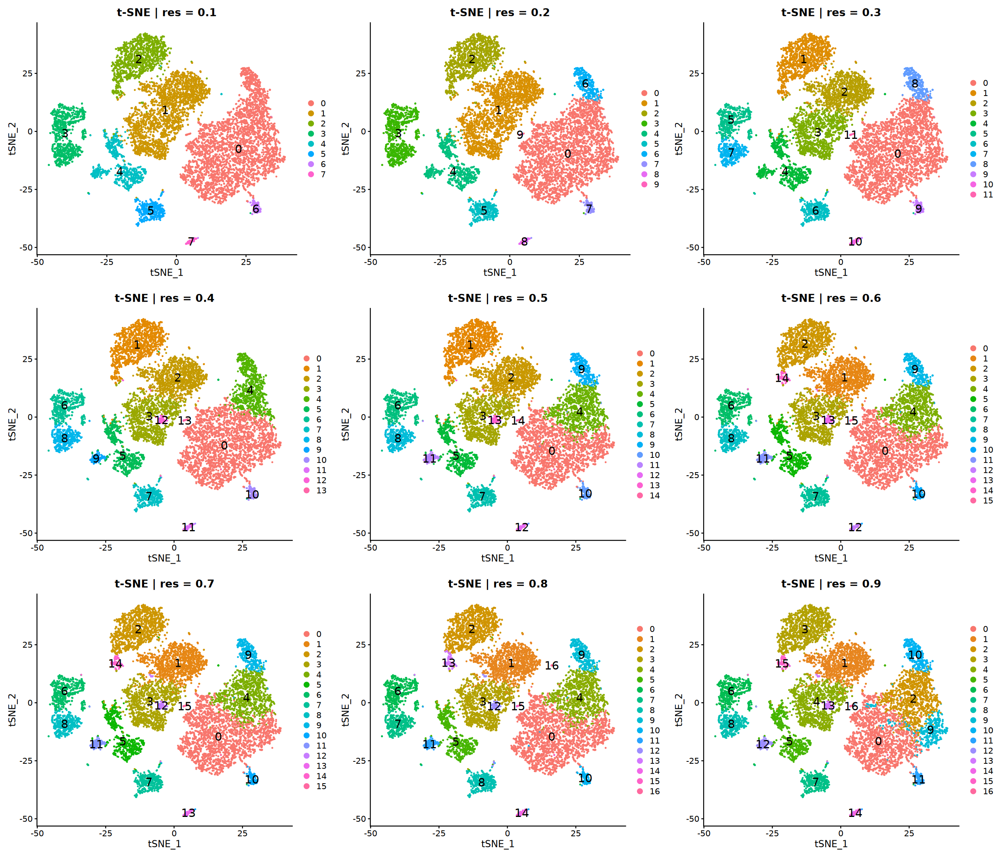

In [83]:
options(repr.plot.width = 21, repr.plot.height = 18)
plot_grid(plotlist = cluster_list$tsne, ncol = 3)

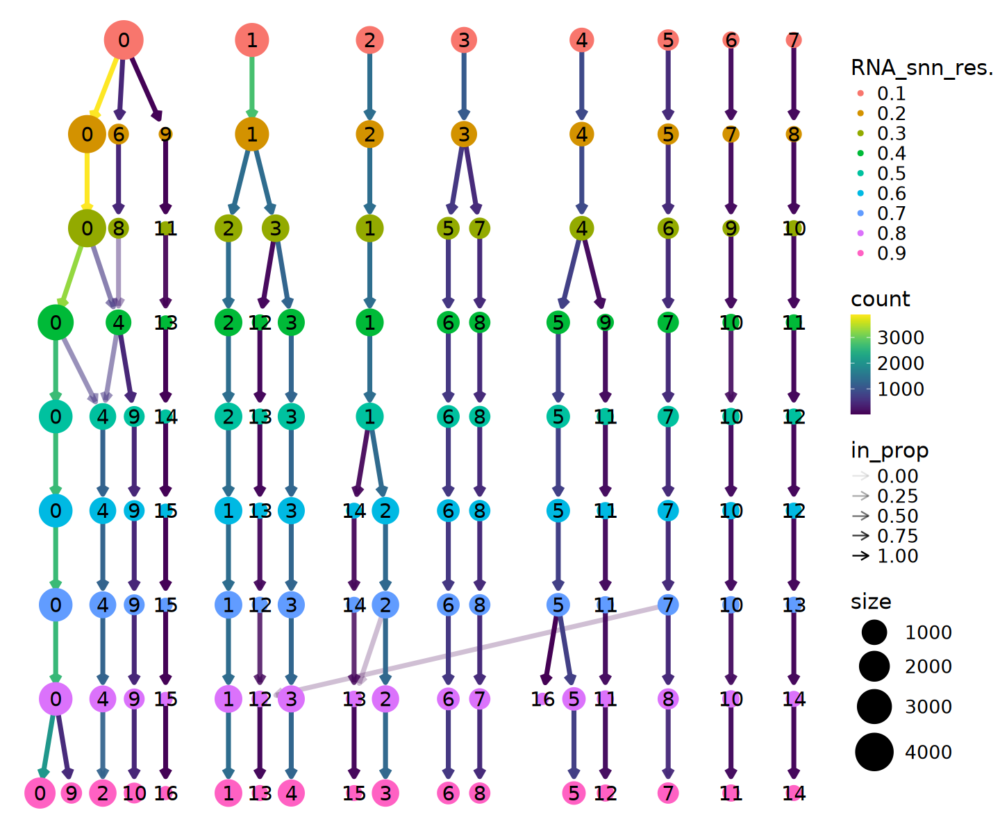

In [84]:
options(repr.plot.width = 12, repr.plot.height = 10)
cluster_list$clustree

In [85]:
scrna <- FindClusters(scrna, resolution = 0.5)

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 11190
Number of edges: 413819

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.9095
Number of communities: 15
Elapsed time: 0 seconds


## 2). Embedding Visualization

In [86]:
# n.neighbors 5 ~ 50, 30
# min.dist 0.001 ~ 0.5, 0.3
plot_umap_params <- function(obj, dims = 10, nn = 30, md = 0.3) {    
    RunUMAP(obj, dims = 1:dims, reduction = "pca", 
            n.neighbors = nn, min.dist = md, verbose = FALSE) |>
    DimPlot(reduction = "umap", group.by = "seurat_clusters",
            label = TRUE, label.size = 6, repel = FALSE) +
        ggtitle(paste0("n.neighbors = ", nn, "\nmin.dist = ", md))
}

In [87]:
p1 <- lapply(
    c(10, 30, 50), plot_umap_params, 
    obj = scrna, dims = nPCs, md = 0.3)
p2 <- lapply(
    c(0.01, 0.3, 0.5), plot_umap_params, 
    obj = scrna, dims = nPCs, nn = 30)

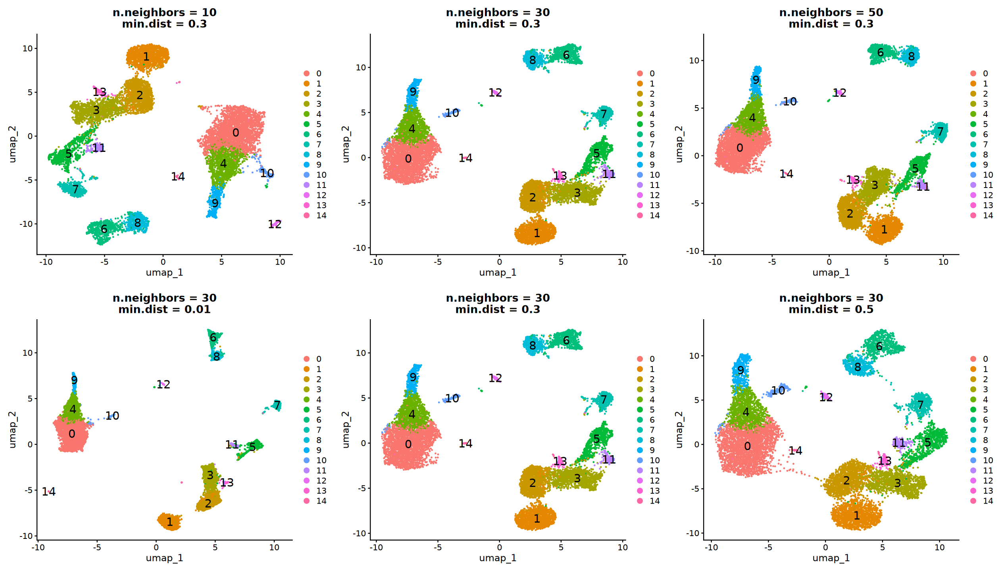

In [88]:
options(repr.plot.width = 21, repr.plot.height = 12)
plot_grid(plot_grid(plotlist = p1, ncol = 3),
          plot_grid(plotlist = p2, ncol = 3), ncol = 1)

In [89]:
# perplexity 5 ~ 50, 30
plot_tsne_params <- function(obj, dims = 10, perplexity = 30) {    
    RunTSNE(obj, dims = 1:dims, reduction = "pca", 
            perplexity = perplexity, verbose = FALSE) |>
    DimPlot(reduction = "tsne", group.by = "seurat_clusters",
            label = TRUE, label.size = 6, repel = FALSE) +
        ggtitle(paste0("perplexity = ", perplexity))
}

In [90]:
p1 <- lapply(
    c(10, 30, 50), plot_tsne_params,
    obj = scrna, dims = nPCs)

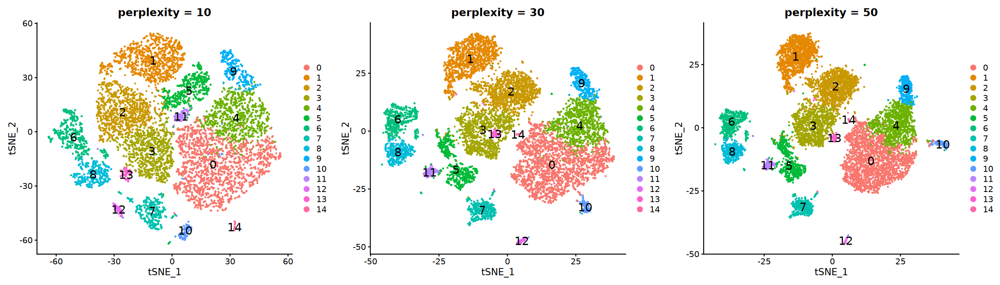

In [91]:
options(repr.plot.width = 21, repr.plot.height = 6)
plot_grid(plotlist = p1, ncol = 3)

In [92]:
scrna <- RunUMAP(
    scrna, dims = seq_len(nPCs), reduction = "pca",
    n.neighbors = 30, min.dist = 0.3, verbose = FALSE)

In [93]:
scrna <- RunTSNE(
    scrna, dims = seq_len(nPCs), reduction = "pca", 
    perplexity = 30, verbose = FALSE)

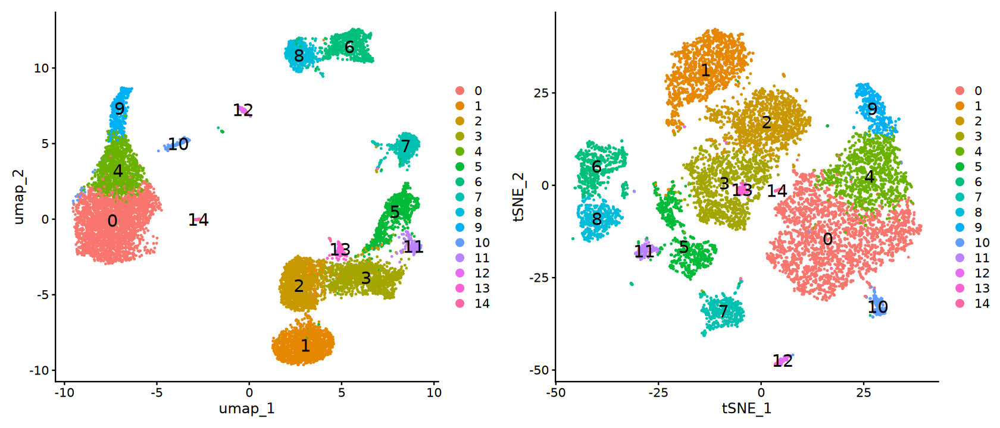

In [94]:
p1 <- DimPlot(
    scrna, reduction = "umap", label = TRUE, 
    label.size = 6, repel = FALSE)
p2 <- DimPlot(
    scrna, reduction = "tsne", label = TRUE, 
    label.size = 6, repel = FALSE)

options(repr.plot.width = 14, repr.plot.height = 6)
plot_grid(p1, p2, ncol = 2)

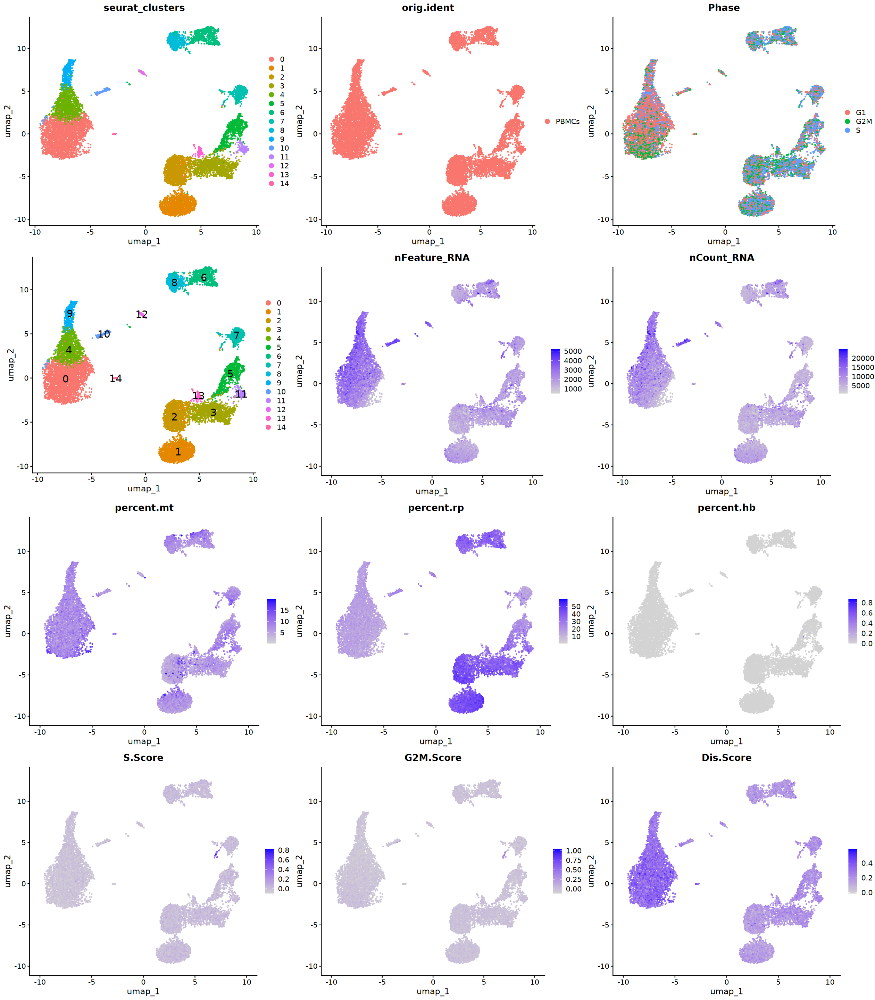

In [95]:
p1 <- DimPlot(
    scrna, reduction = "umap", combine = FALSE,
    group.by = c("seurat_clusters", "orig.ident", "Phase"))
p2 <- DimPlot(
    scrna, reduction = "umap", label = TRUE, 
    label.size = 6)
p3 <- FeaturePlot(
    scrna, reduction = "umap", combine = FALSE,
    features = c("nFeature_RNA", "nCount_RNA"))
p4 <- FeaturePlot(
    scrna, reduction = "umap", combine = FALSE,
    features = c("percent.mt", "percent.rp", "percent.hb", 
                 "S.Score", "G2M.Score", "Dis.Score"))

options(repr.plot.width = 21, repr.plot.height = 24)
plot_grid(plotlist = c(p1, p2, p3, p4), ncol = 3)

In [96]:
scrna

An object of class Seurat 
42815 features across 11190 samples within 2 assays 
Active assay: RNA (22302 features, 3000 variable features)
 3 layers present: counts, data, scale.data
 1 other assay present: SCT
 3 dimensional reductions calculated: pca, umap, tsne

In [97]:
saveRDS(scrna, file.path(
    data_dir, "result", "s9_cluster_seurat_V5.rds"))

# 10. Cluster Biomarkers

In [98]:
sc.markers <- FindAllMarkers(
    scrna, logfc.threshold = log2(1.2), min.pct = 0.25, 
    only.pos = TRUE)

Calculating cluster 0

Calculating cluster 1

Calculating cluster 2

Calculating cluster 3

Calculating cluster 4

Calculating cluster 5

Calculating cluster 6

Calculating cluster 7

Calculating cluster 8

Calculating cluster 9

Calculating cluster 10

Calculating cluster 11

Calculating cluster 12

Calculating cluster 13

Calculating cluster 14



In [99]:
head(sc.markers)

,p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>
S100A12,0,4.915454,0.974,0.136,0,0,S100A12
VCAN,0,4.302325,0.994,0.190,0,0,VCAN
CD14,0,3.432232,0.964,0.161,0,0,CD14
AC020656.1,0,3.256140,0.982,0.202,0,0,AC020656.1
MS4A6A,0,2.694164,0.977,0.199,0,0,MS4A6A
CD36,0,3.288713,0.962,0.196,0,0,CD36


In [100]:
sc.markers.filt <- sc.markers |> 
    filter(p_val_adj < 0.01, 
           avg_log2FC > log2(1.2), 
           pct.1 - pct.2 > 0.2)

In [101]:
sc.markers.filt |> 
    group_by(cluster) |> 
    summarise(length(gene)) |>
    t()

cluster,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
length(gene),1084,106,73,123,1520,133,234,202,152,1670,2211,169,1510,101,326


In [102]:
top10 <- sc.markers.filt |> group_by(cluster) |> 
    top_n(10, wt = avg_log2FC)

top3 <- sc.markers.filt |> group_by(cluster) |> 
    top_n(3, wt = avg_log2FC)

## Visualization

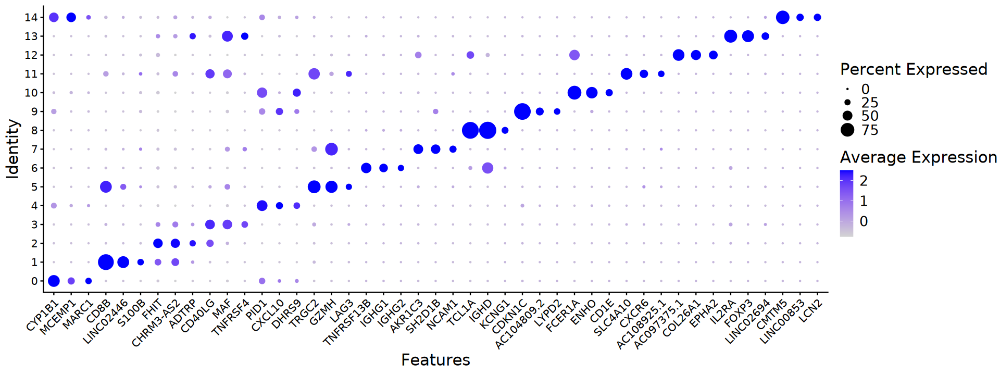

In [103]:
options(repr.plot.width = 16, repr.plot.height = 6)
DotPlot(scrna, features = unique(top3$gene), dot.scale = 8) + 
    RotatedAxis() + 
    theme(axis.title = element_text(size = 18),
          axis.text = element_text(size = 12),
          legend.title = element_text(size = 18), 
          legend.text = element_text(size = 16))

In [104]:
plot_dir <- file.path(
    data_dir, "visualization", "p7.1_cluster_top10_genes")

if (!dir.exists(plot_dir)) {
    dir.create(plot_dir, recursive = TRUE)
}

In [105]:
for (index in seq(1:length(top10$gene))) {
    p1 <- VlnPlot(scrna, features = top10$gene[index])
    p2 <- FeaturePlot(
        scrna, reduction = "umap", features = top10$gene[index])
    p3 <- FeaturePlot(
        scrna, reduction = "tsne", features = top10$gene[index])
    pg <- plot_grid(p1, plot_grid(p2, p3, ncol = 2), ncol = 1)
    
    file.path(plot_dir, paste0(
        "cluster_", top10$cluster[index], "_", top10$gene[index], ".png")) |>
        ggsave(plot = pg, width = 9, height = 8)
}

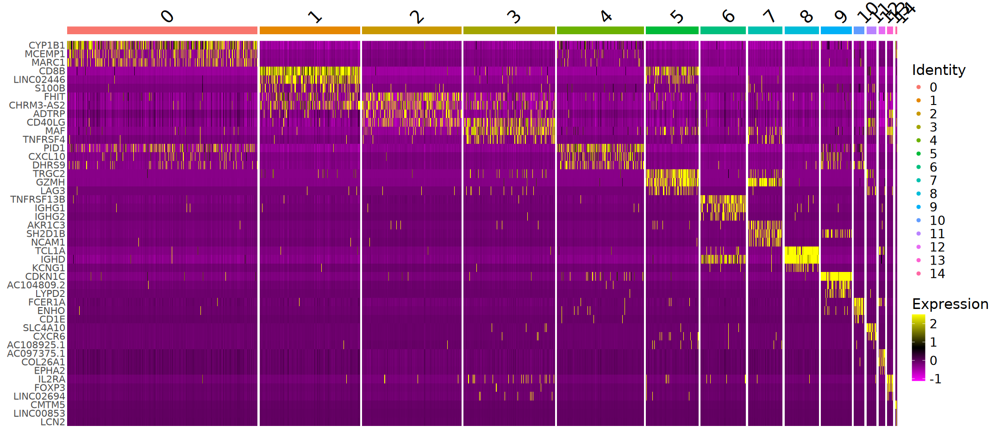

In [106]:
options(repr.plot.width = 18, repr.plot.height = 8)
DoHeatmap(scrna, slot = "scale.data", 
          features = top3$gene, size = 8) +
    # scale_fill_gradientn(colors = PurpleAndYellow()) +
    theme(axis.text = element_text(size = 12),
          legend.title = element_text(size = 18), 
          legend.text = element_text(size = 16))

# 11. Cell-type Annotation

## a). Automatic

In [107]:
suppressPackageStartupMessages(library(SingleR))

In [108]:
ref_pbmc <- file.path(
    "~/data1/single_cell_dataset/PBMCs/Hs_PBMC_GSE164378", 
    "matrix", "RNA_3P", "RNA") |>
    Read10X()

In [109]:
ref_metadata <- file.path(
    "~/data1/single_cell_dataset/PBMCs/Hs_PBMC_GSE164378", 
    "GSE164378_sc.meta.data_3P.csv.gz") |>
    read.csv(header = TRUE, row.names = 1) |>
    select(celltype.l1, celltype.l2, celltype.l3)

In [110]:
ref_pbmc <- SingleCellExperiment(
    list(counts = ref_pbmc), 
    colData = ref_metadata)

ref_pbmc <- scuttle::logNormCounts(ref_pbmc)

ref_pbmc

class: SingleCellExperiment 
dim: 33538 161764 
metadata(0):
assays(2): counts logcounts
rownames(33538): MIR1302-2HG FAM138A ... AC213203.1 FAM231C
rowData names(0):
colnames(161764): L1_AAACCCAAGAAACTCA L1_AAACCCAAGACATACA ...
  E2L8_TTTGTTGGTTGGCTAT E2L8_TTTGTTGTCTCATGGA
colData names(4): celltype.l1 celltype.l2 celltype.l3 sizeFactor
reducedDimNames(0):
mainExpName: NULL
altExpNames(0):

In [111]:
# SingleR performs the prediction of celltypes for each cluster
celltype.SingleR <- LayerData(
    scrna, assay = "RNA", layer = "data") |>
    SingleR(ref = ref_pbmc, labels = ref_pbmc$celltype.l1, 
            clusters = scrna$seurat_clusters,
            de.method = "wilcox")

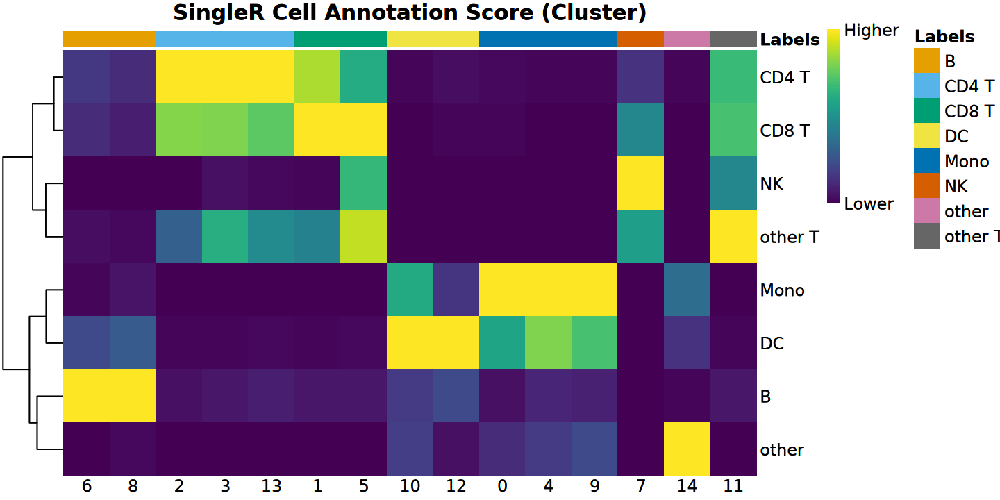

In [112]:
options(repr.plot.width = 12, repr.plot.height = 6)
plotScoreHeatmap(
    celltype.SingleR, show_colnames = TRUE, 
    main = "SingleR Cell Annotation Score (Cluster)",
    angle_col = 0, fontsize = 14)

In [113]:
scrna$celltype.SingleR.l1 <- 
    celltype.SingleR$labels[scrna$seurat_clusters]

In [114]:
# SingleR performs the prediction of celltypes for each cluster
celltype.SingleR <- LayerData(
    scrna, assay = "RNA", layer = "data") |>
    SingleR(ref = ref_pbmc, labels = ref_pbmc$celltype.l2, 
            clusters = scrna$seurat_clusters,
            de.method = "wilcox")

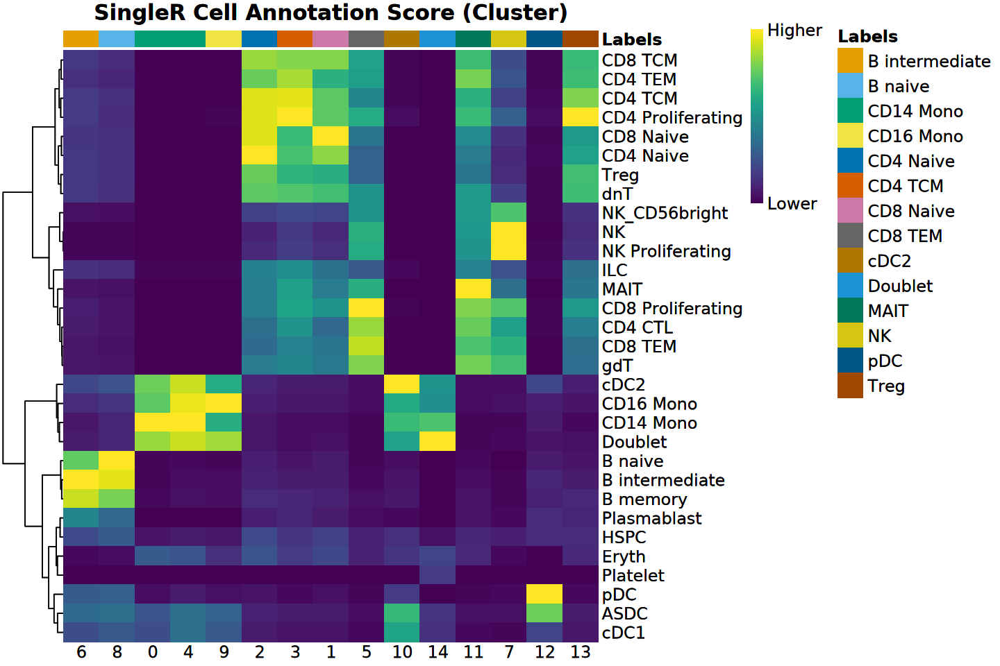

In [115]:
options(repr.plot.width = 12, repr.plot.height = 8)
plotScoreHeatmap(
    celltype.SingleR, show_colnames = TRUE, 
    main = "SingleR Cell Annotation Score (Cluster)",
    angle_col = 0, fontsize = 14)

In [116]:
scrna$celltype.SingleR.l2 <- 
    celltype.SingleR$labels[scrna$seurat_clusters]

In [117]:
# SingleR performs the prediction of celltypes for each cluster
celltype.SingleR <- LayerData(
    scrna, assay = "RNA", layer = "data") |>
    SingleR(ref = ref_pbmc, labels = ref_pbmc$celltype.l3, 
            clusters = scrna$seurat_clusters,
            de.method = "wilcox")

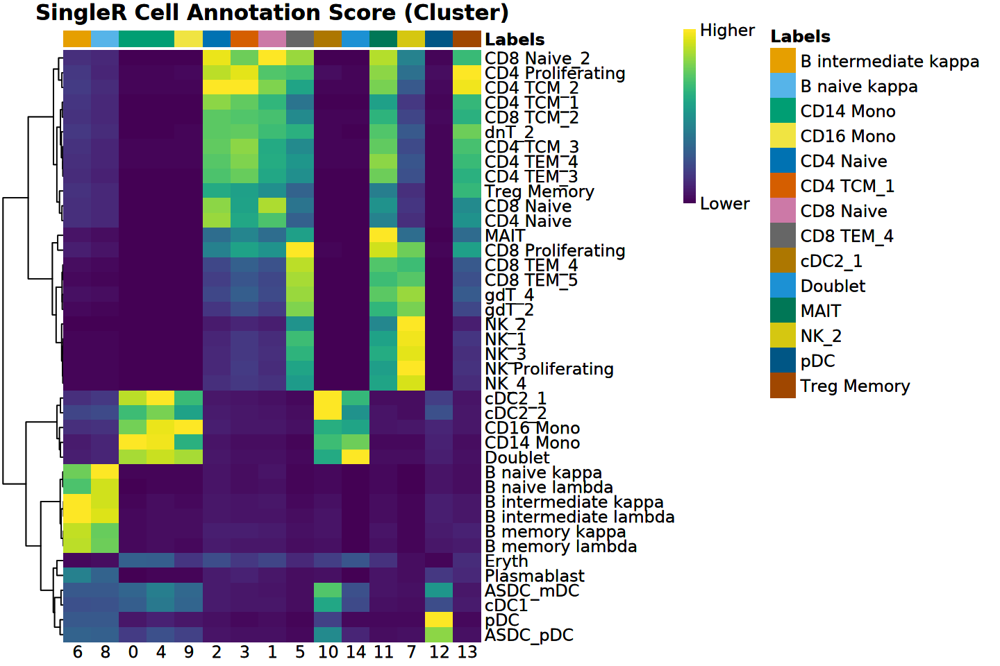

In [118]:
options(repr.plot.width = 12, repr.plot.height = 8)
plotScoreHeatmap(
    celltype.SingleR, show_colnames = TRUE, 
    main = "SingleR Cell Annotation Score (Cluster)",
    angle_col = 0, fontsize = 14)

In [119]:
scrna$celltype.SingleR.l3 <- 
    celltype.SingleR$labels[scrna$seurat_clusters]

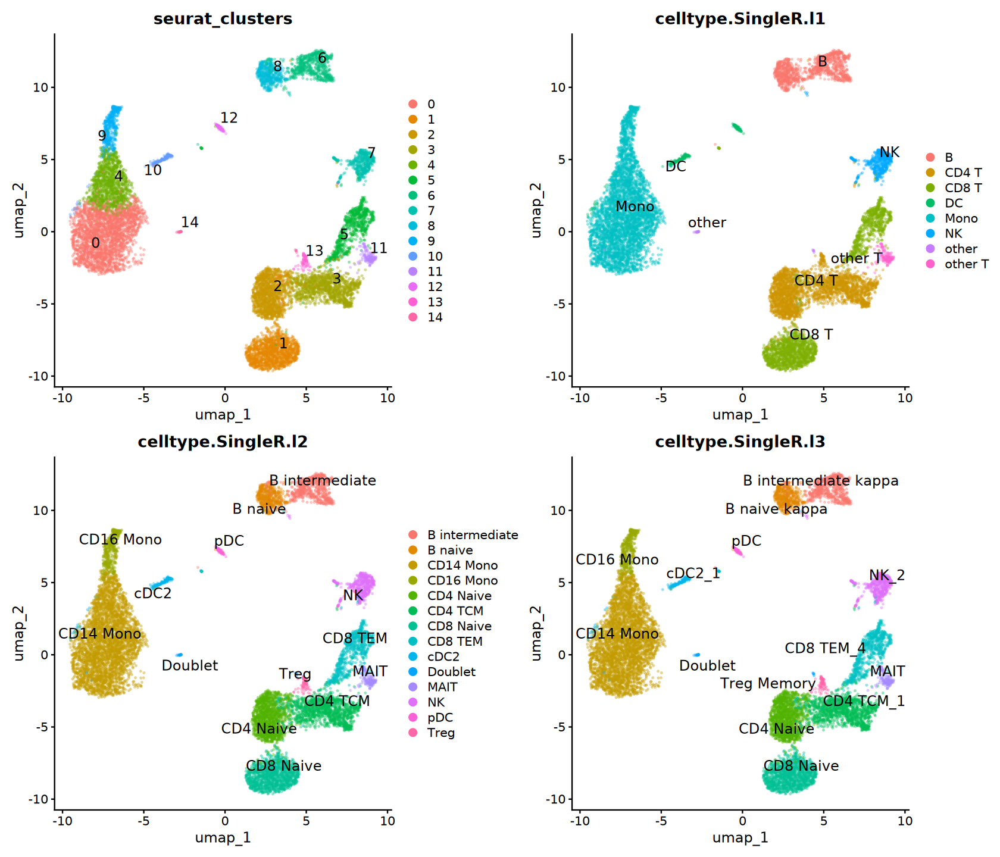

In [120]:
options(repr.plot.width = 14, repr.plot.height = 12)
DimPlot(scrna, reduction = "umap", 
        group.by = c("seurat_clusters", "celltype.SingleR.l1", 
                     "celltype.SingleR.l2", "celltype.SingleR.l3"), 
        label = TRUE, repel = TRUE, label.size = 5, 
        pt.size = 0.3,  alpha = 0.3) &
    NoLegend()

## b). Manual

In [121]:
gene_list <- sc.markers.filt |> 
    group_by(cluster) |> 
    top_n(10, wt = avg_log2FC) |>
    summarise(genes = paste0('"', gene, '"', collapse = ", ")) |>
    mutate(out = paste0("cluster_", cluster, ": ", genes)) |> 
    pull(out)

In [122]:
gene_list |> cat(sep = "\n")

cluster_0: "S100A12", "S100A8", "CYP1B1", "THBS1", "QPCT", "CRISPLD2", "STEAP4", "MCEMP1", "CLEC4D", "MARC1"
cluster_1: "CD8B", "CD8A", "KLRK1", "LINC02446", "NELL2", "LRRN3", "S100B", "PDE3B", "PASK", "SCGB3A1"
cluster_2: "CCR7", "LEF1", "FHIT", "TRABD2A", "CHRM3-AS2", "ADTRP", "TRAT1", "CD40LG", "FBLN5", "LINC01550"
cluster_3: "AQP3", "GPR183", "INPP4B", "CD40LG", "MAF", "TNFRSF4", "CD28", "GATA3", "SLAMF1", "ANK3"
cluster_4: "LGALS2", "CPVL", "APOBEC3A", "PEA15", "PID1", "SERPING1", "CLEC10A", "CXCL10", "SRC", "DHRS9"
cluster_5: "CCL5", "KLRG1", "TRGC2", "GZMH", "LINC01871", "FCRL6", "GZMK", "A2M-AS1", "LAG3", "EOMES"
cluster_6: "CD24", "TNFRSF13B", "FCRL2", "LINC01857", "IGHA1", "CPNE5", "IGHG1", "IGHG3", "LINC01781", "IGHG2"
cluster_7: "KLRF1", "SPON2", "AKR1C3", "SH2D1B", "NMUR1", "NCR1", "NCAM1", "IL18RAP", "LINC00299", "RNF165"
cluster_8: "TCL1A", "IGHD", "LINC00926", "FCER2", "FCRL1", "CD72", "COL19A1", "CD200", "PCDH9", "KCNG1"
cluster_9: "CDKN1C", "HES4", "FCGR3A", "CTSL", "

Picking joint bandwidth of 0.197

Picking joint bandwidth of 0.0175

Picking joint bandwidth of 0.0115

Picking joint bandwidth of 0.0557

Picking joint bandwidth of 0.0405

Picking joint bandwidth of 0.0911



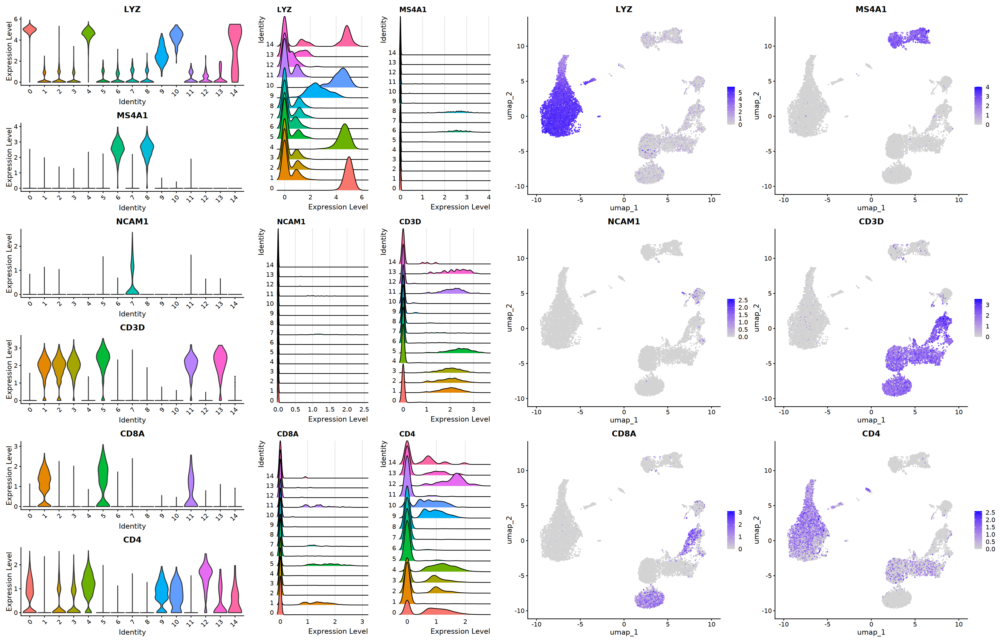

In [123]:
geneset <- c("LYZ", "MS4A1", "NCAM1", "CD3D", "CD8A", "CD4")
p1 <- VlnPlot(
    scrna, features = geneset, ncol = 1, pt.size = 0)
p2 <- RidgePlot(
    scrna, features = geneset, ncol = 2)
p3 <- FeaturePlot(
    scrna, reduction = "umap", features = geneset, ncol = 2)

options(repr.plot.width = 28, repr.plot.height = 18)
plot_grid(p1, p2, p3, ncol = 3, rel_widths = c(1, 1, 2))

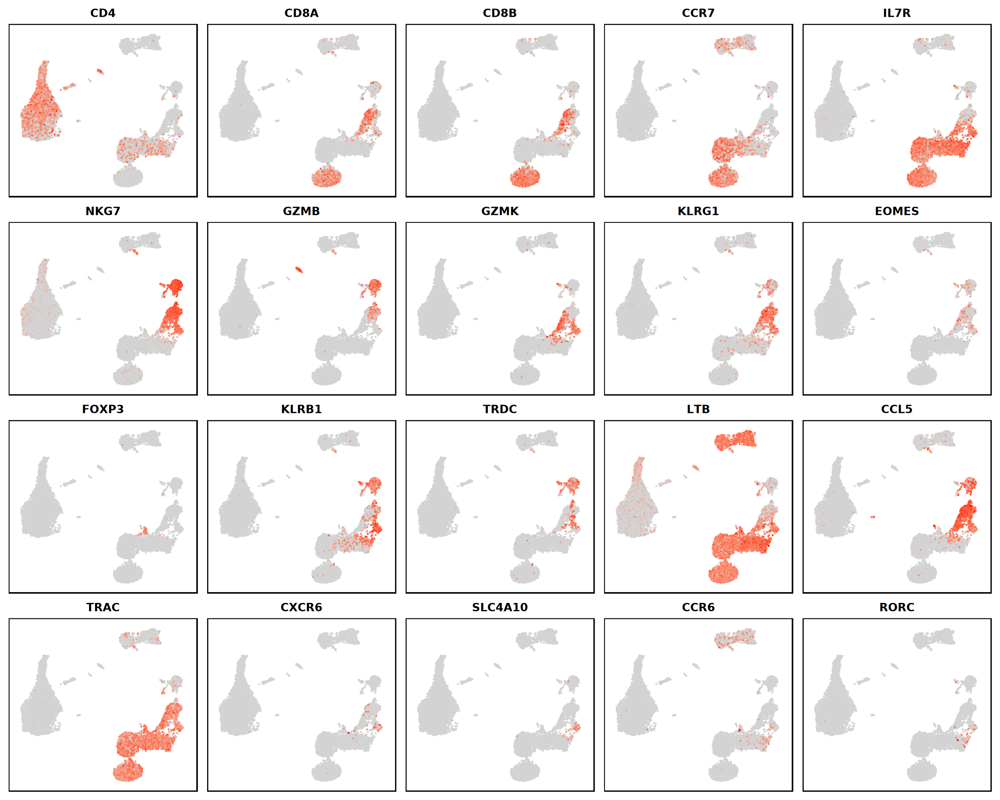

In [124]:
geneset <- c("CD4", "CD8A", "CD8B", "CCR7", "IL7R", 
             "NKG7", "GZMB", "GZMK", "KLRG1", "EOMES", 
             "FOXP3", "KLRB1", "TRDC", "LTB", "CCL5",
             "TRAC", "CXCR6", "SLC4A10", "CCR6", "RORC")

options(repr.plot.width = 20, repr.plot.height = 16)
FeaturePlot(scrna, features = geneset, reduction = "umap", 
            cols = c("lightgrey", 'red'), ncol = 5) & 
    NoLegend() & NoAxes() &
    theme(panel.border = element_rect(color = "black", linewidth = 1))

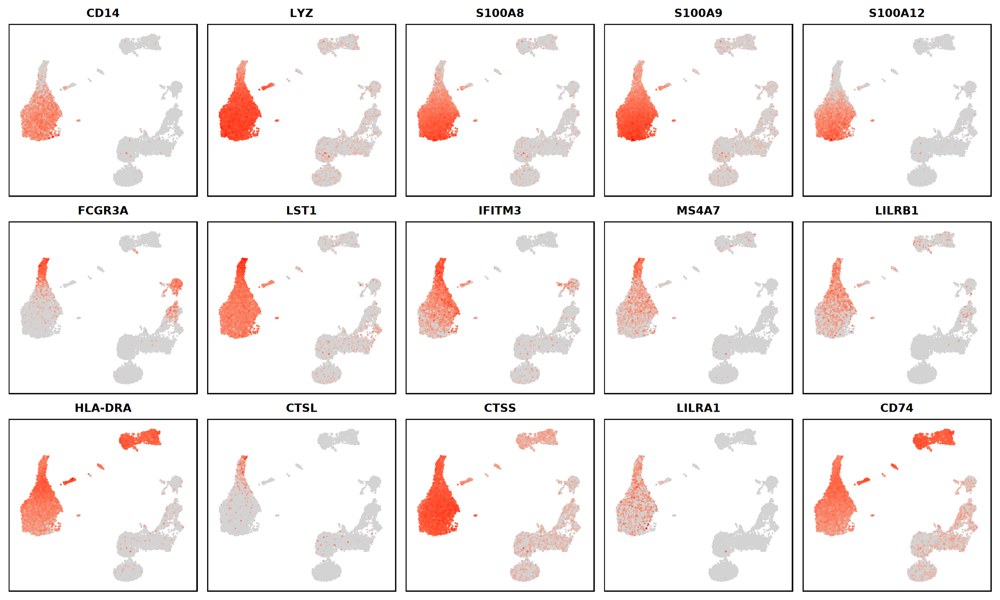

In [125]:
# Classical monocytes: "CD14", "LYZ", "S100A8", "S100A9", "S100A12"
# Non-classical monocytes: "FCGR3A", "LST1", "IFITM3", "MS4A7", "LILRB1"
# Intermediate monocytes: "CD14", "FCGR3A", "HLA-DRA", "HLA-DPB1", "CTSL", "CTSS", "LILRA1", "CD74"

geneset <- c("CD14", "LYZ", "S100A8", "S100A9", "S100A12",
             "FCGR3A", "LST1", "IFITM3", "MS4A7", "LILRB1",
             "HLA-DRA", "CTSL", "CTSS", "LILRA1", "CD74")

options(repr.plot.width = 20, repr.plot.height = 12)
FeaturePlot(scrna, features = geneset, reduction = "umap", 
            cols = c("lightgrey", 'red'), ncol = 5) & 
    NoLegend() & NoAxes() &
    theme(panel.border = element_rect(color = "black", linewidth = 1))

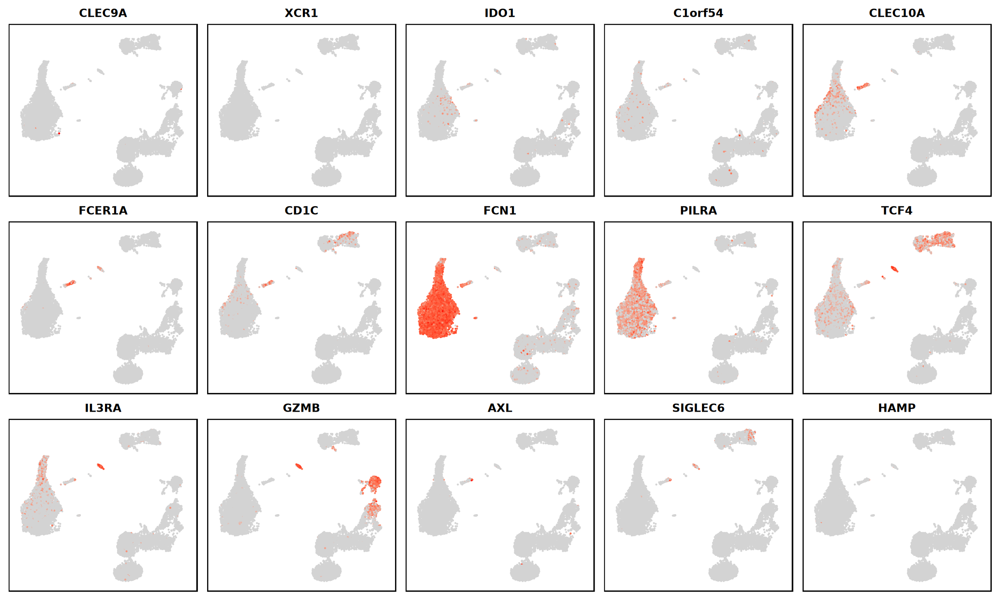

In [126]:
# cDC1: "CLEC9A", "XCR1", "IDO1", "C1orf54"
# cDC2: "CD1C", "FCN1", "PILRA"
# pDC: "GZMB", "TCF4", "IL3RA", "CLEC4C"
# ASDC: "AXL", "SIGLEC6", "HAMP"

geneset <- c("CLEC9A", "XCR1", "IDO1", "C1orf54",
             "CLEC10A", "FCER1A", "CD1C", "FCN1", "PILRA",
             "TCF4", "IL3RA", "GZMB",
             "AXL", "SIGLEC6", "HAMP")

options(repr.plot.width = 20, repr.plot.height = 12)
FeaturePlot(scrna, features = geneset, reduction = "umap", 
            cols = c("lightgrey", 'red'), ncol = 5) & 
    NoLegend() & NoAxes() &
    theme(panel.border = element_rect(color = "black", linewidth = 1))

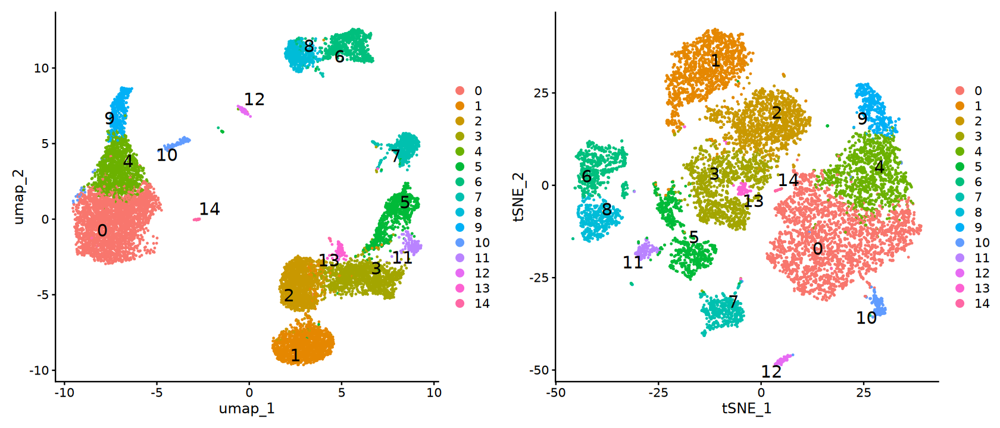

In [127]:
p1 <- DimPlot(
    scrna, reduction = "umap", label = TRUE, 
    label.size = 6, repel = TRUE)
p2 <- DimPlot(
    scrna, reduction = "tsne", label = TRUE, 
    label.size = 6, repel = TRUE)

options(repr.plot.width = 14, repr.plot.height = 6)
plot_grid(p1, p2, ncol = 2)

In [128]:
# Cell annotation with ChatGPT assistance
cluster2celltype <- c(
    "0" = "Classical Monocytes", "1" = "Naïve/Memory CD8 T", "2" = "Naïve/Memory CD4 T",
    "3" = "Activated CD4 T", "4" = "Intermediate Monocytes", "5" = "Cytotoxic CD8 T",
    "6" = "Plasmablast", "7" = "NK Cells", "8" = "Naive B",
    "9" = "Non-classical Monocytes", "10" = "Dendritic Cells (cDC2)", "11" = "MAIT", 
    "12" = "pDC", "13" = "Treg", "14" = "Platelets")

# Mucosal-Associated Invariant T cells (MAIT)

In [129]:
scrna@meta.data$celltype <- 
    cluster2celltype[as.character(scrna$seurat_clusters)]

scrna <- RenameIdents(scrna, cluster2celltype)

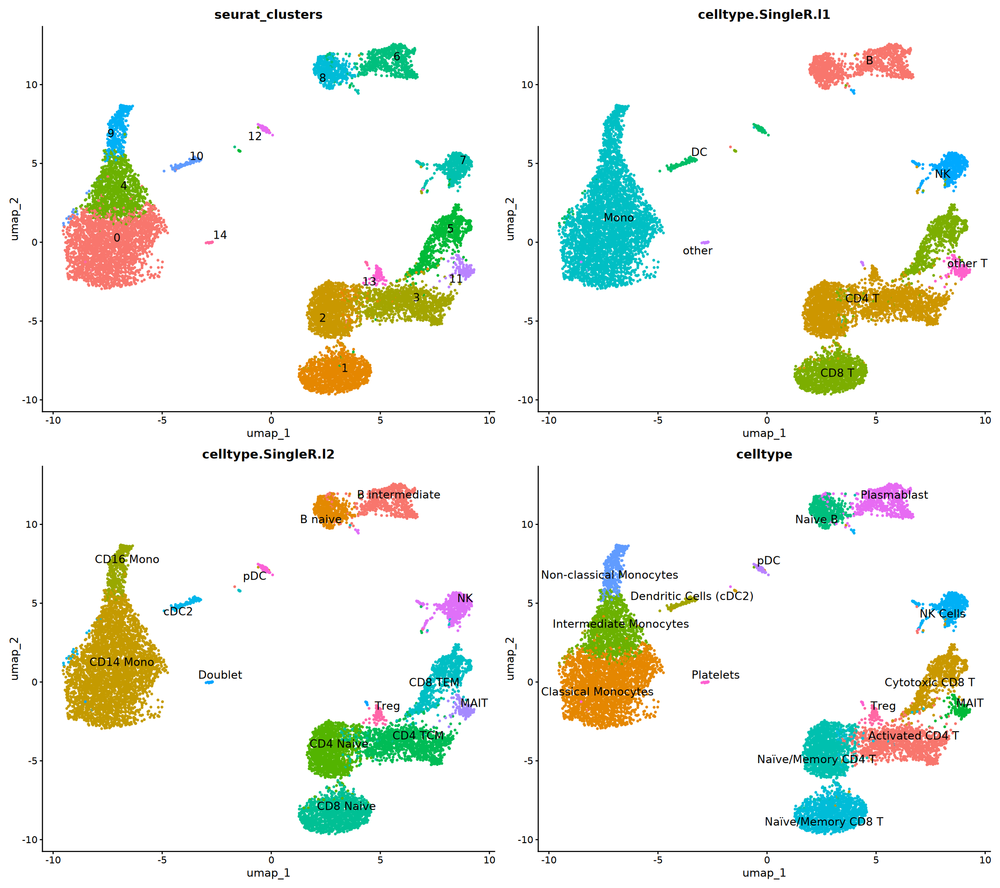

In [130]:
options(repr.plot.width = 18, repr.plot.height = 16)
DimPlot(scrna, reduction = "umap",
        group.by = c("seurat_clusters", "celltype.SingleR.l1", 
                     "celltype.SingleR.l2", "celltype"), 
        label = TRUE, repel = TRUE, label.size = 5, 
        pt.size = 0.5) & 
    NoLegend()

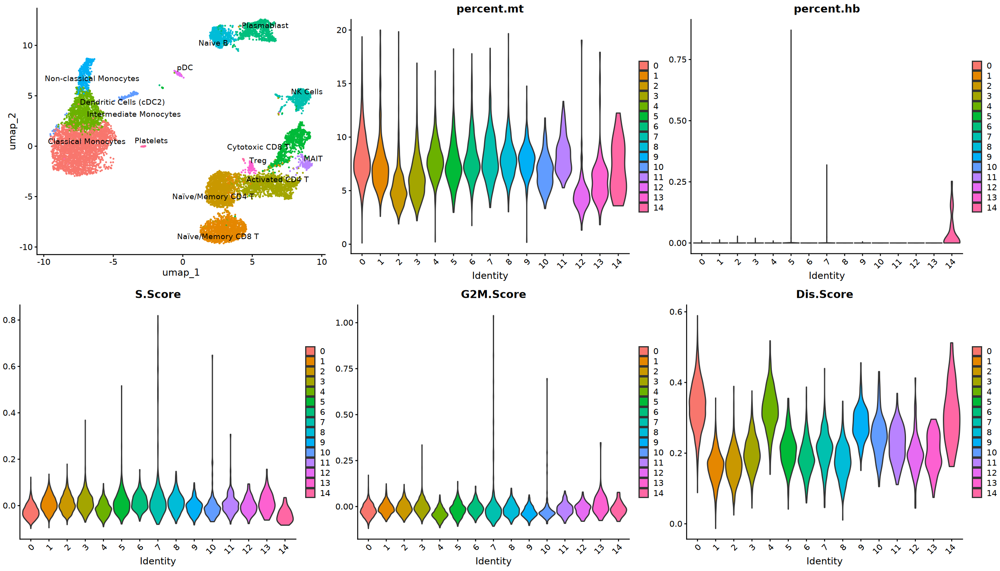

In [131]:
p1 <- DimPlot(
    scrna, reduction = "umap", label = TRUE, 
    label.size = 4, repel = TRUE) & NoLegend()
p2 <- VlnPlot(
    scrna, features = c("percent.mt", "percent.hb"), 
    group.by = "seurat_clusters", pt.size = 0, combine = FALSE)
p3 <- VlnPlot(
    scrna, features = c("S.Score", "G2M.Score", "Dis.Score"), 
    group.by = "seurat_clusters", pt.size = 0, combine = FALSE)

options(repr.plot.width = 21, repr.plot.height = 12)
plot_grid(plotlist = c(p1, p2, p3), ncol = 3)

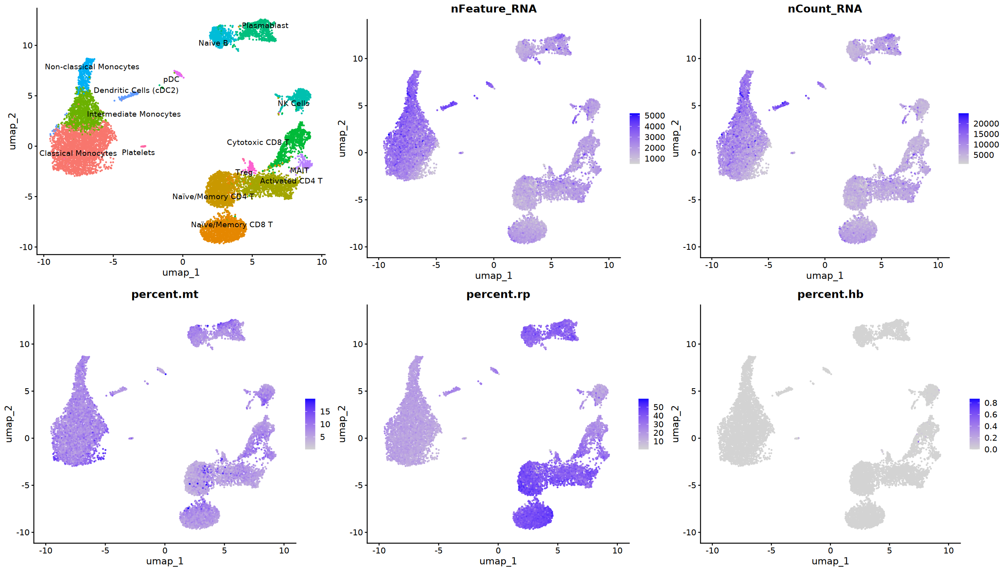

In [132]:
p1 <- DimPlot(
    scrna, reduction = "umap", label = TRUE, 
    label.size = 4, repel = TRUE) & NoLegend()
p2 <- FeaturePlot(
    scrna, reduction = "umap", combine = FALSE,
    features = c("nFeature_RNA", "nCount_RNA", "percent.mt", 
                 "percent.rp", "percent.hb"))

options(repr.plot.width = 21, repr.plot.height = 12)
plot_grid(plotlist = c(p1, p2), ncol = 3)

In [133]:
saveRDS(scrna, file.path(
    data_dir, "result", "s11_annotation_seurat_V5.rds"))